In [1]:
import numpy as np
from scipy.io import loadmat
import warnings
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit

In [2]:
!pip install pandas
!pip install resonator_tools

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root, least_squares
from scipy.special import ellipk
from scipy.constants import mu_0, epsilon_0
from resonator_tools import circuit

In [4]:
import os
os.chdir(r"C:\Users\chowdhf4\.vscode\Tunable-Coupler\TC-Main-003")   # paste your copied path here
print(os.getcwd())
print(os.listdir())

C:\Users\chowdhf4\.vscode\Tunable-Coupler\TC-Main-003
['Current_v3.mat', 'f0_guess.mat', 'f0_guess_v2.mat', 'f0_guess_v3.mat', 'f0_guess_v4.mat', 'f0_guess_v5.mat', 'Freq.mat', 'Freq_v2.mat', 'I1.mat', 'S21_complex_wbg_wtd.mat', 'S21_corr_complex.mat', 'S21_corr_complex_v2.mat', 'TC-Main-003_fit-v1.ipynb', 'TC-Main-003_fit-v2.ipynb']


In [5]:
# Files
File_Complex     = 'S21_corr_complex_v2.mat'
FILE_FREQ        = 'Freq.mat'
FILE_CURRENT     = 'I1.mat'
File_F0_Guess    = 'f0_guess_v4.mat'

def mat_to_1d_vector(d):
    for k, v in d.items():
        if k.startswith('__'): continue
        arr = np.asarray(v).squeeze()
        if arr.ndim == 1 and np.isrealobj(arr):
            return arr
    raise ValueError("No 1D array found in .mat file")

Mat_Freq     = loadmat(FILE_FREQ, squeeze_me=True)
Mat_Current  = loadmat(FILE_CURRENT, squeeze_me=True)
Mat_Complex  = loadmat(File_Complex, squeeze_me=True)
Mat_F0_Guess = loadmat(File_F0_Guess, squeeze_me=True)
Mat_F0_Guess_v2 = loadmat('f0_guess_v5.mat', squeeze_me=True)
S21_Complex_full = Mat_Complex['S21_corrected'] 
Freq = Mat_Freq['Freq_lp']
I1_full  = Mat_Current['I1']
f0_guess = Mat_F0_Guess['dips']
f0_guess_v2 = Mat_F0_Guess_v2['dips']
#Mat_Complex

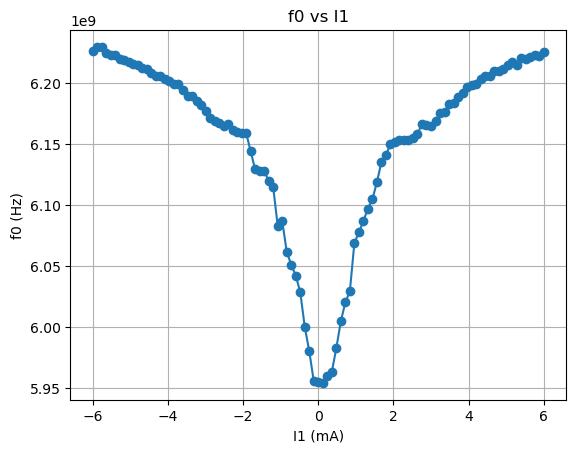

In [6]:
plt.plot(I1_full, f0_guess, '-o')
# plt.plot(I1_full, f0_guess_v2, '-o')
plt.xlabel('I1 (mA)')
plt.ylabel('f0 (Hz)')
plt.title('f0 vs I1')
plt.grid()
plt.show()

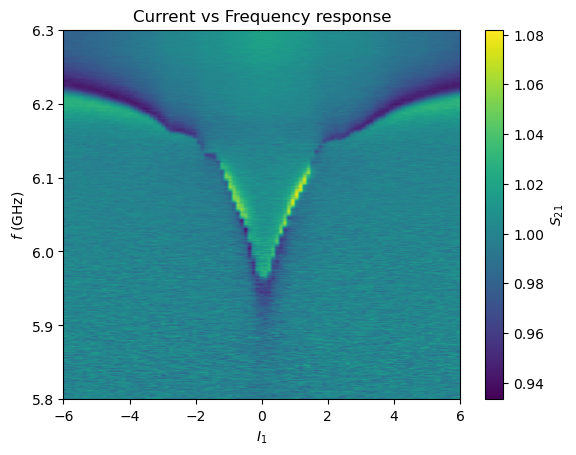

In [7]:
plt.imshow(np.abs(S21_Complex_full), aspect='auto', origin='lower', extent=[I1_full[0], I1_full[-1], Freq[0]/1e9, Freq[-1]/1e9])
plt.colorbar(label=r'$S_{21}$')
plt.xlabel(r'$I_1$')
plt.ylabel(r'$f$ (GHz)')
plt.title(r'Current vs Frequency response')
plt.show()

I1=-1.32 mA: f0=6119499999.999999 Hz, i=39


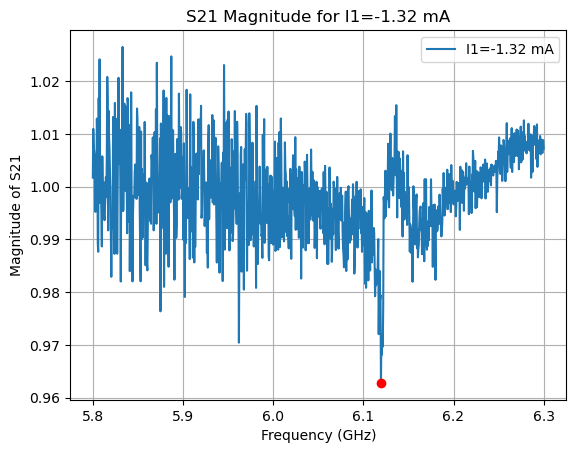

I1=-1.2 mA: f0=6114500000.000000 Hz, i=40


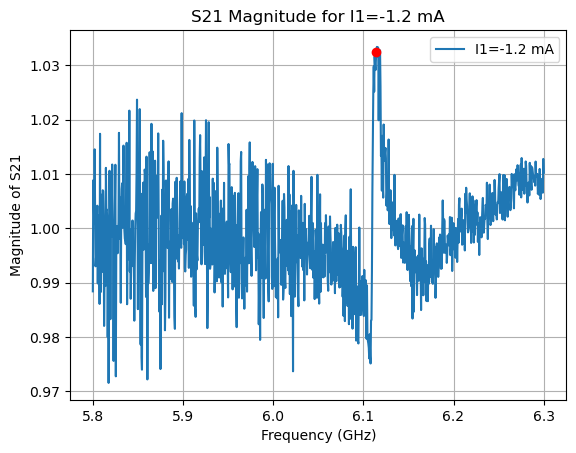

I1=-1.08 mA: f0=6083000000.000000 Hz, i=41


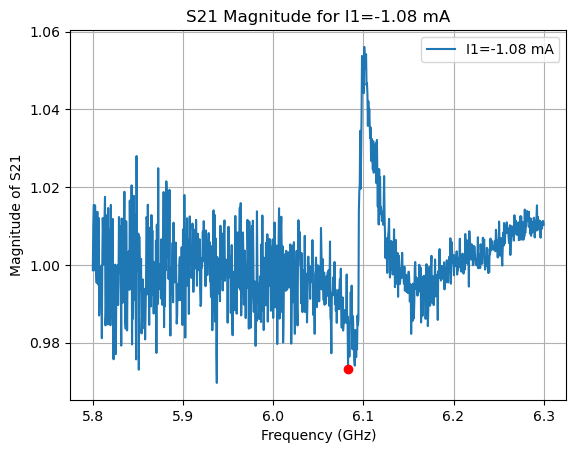

I1=-0.96 mA: f0=6087000000.000000 Hz, i=42


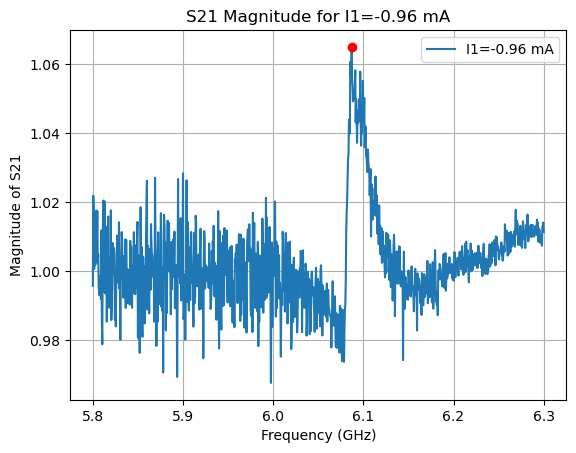

I1=-0.84 mA: f0=6061500000.000000 Hz, i=43


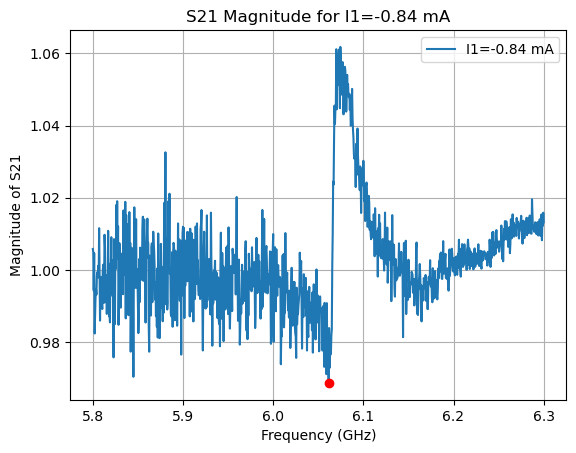

I1=-0.72 mA: f0=6051000000.000000 Hz, i=44


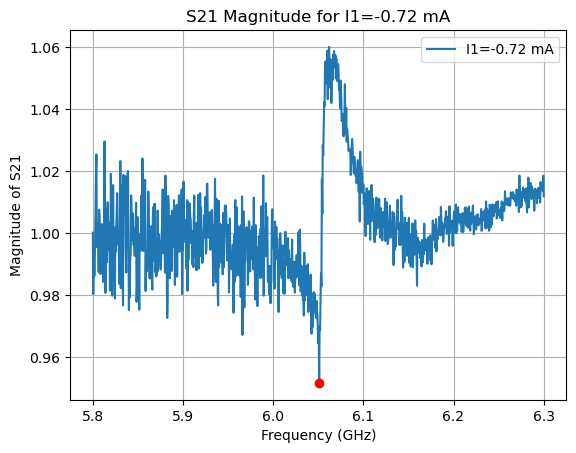

I1=-0.6 mA: f0=6042000000.000000 Hz, i=45


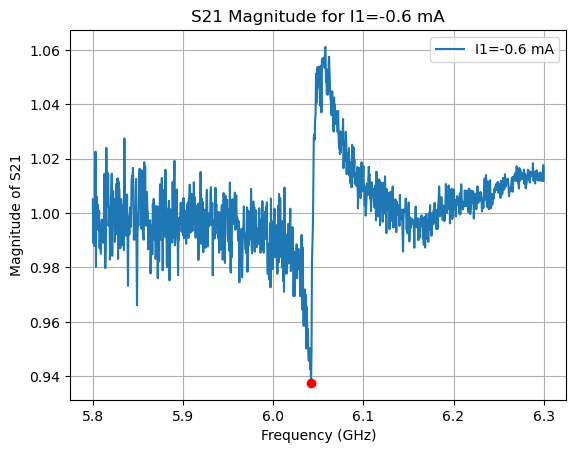

I1=-0.48 mA: f0=6028500000.000000 Hz, i=46


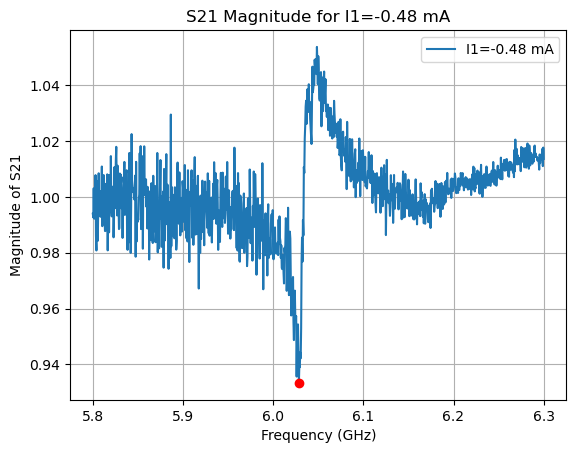

I1=-0.36 mA: f0=6000000000.000000 Hz, i=47


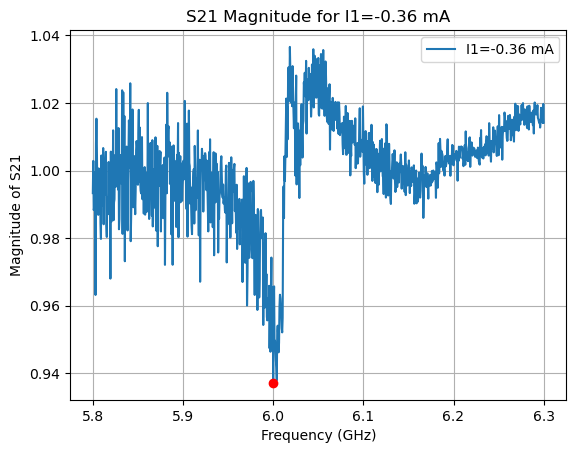

I1=-0.24 mA: f0=5980000000.000000 Hz, i=48


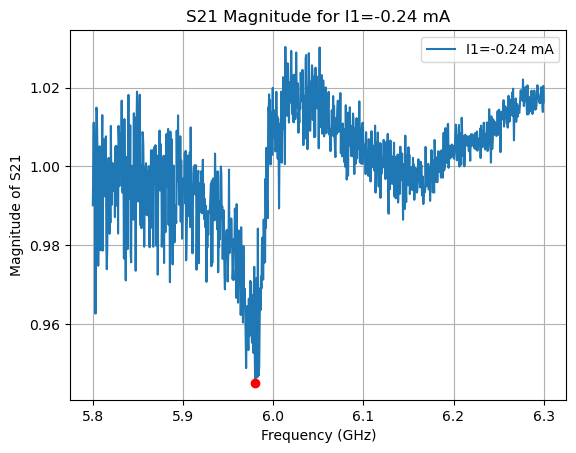

I1=-0.12 mA: f0=5955500000.000000 Hz, i=49


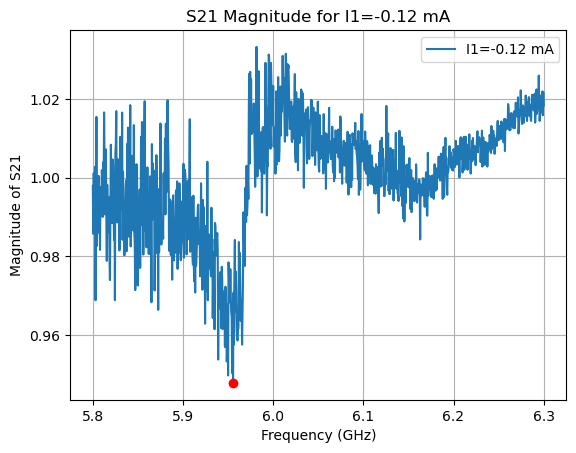

I1=0 mA: f0=5954499999.999999 Hz, i=50


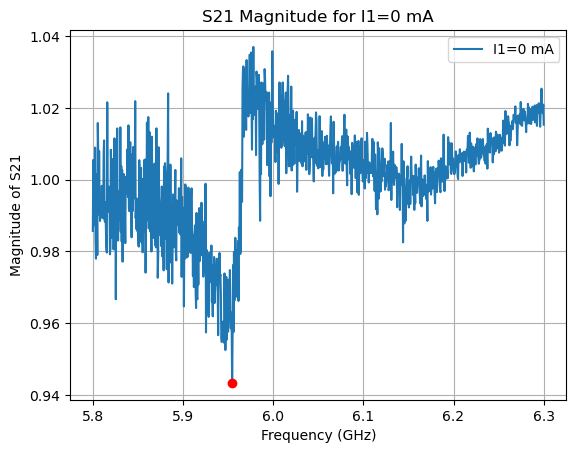

I1=0.12 mA: f0=5954000000.000000 Hz, i=51


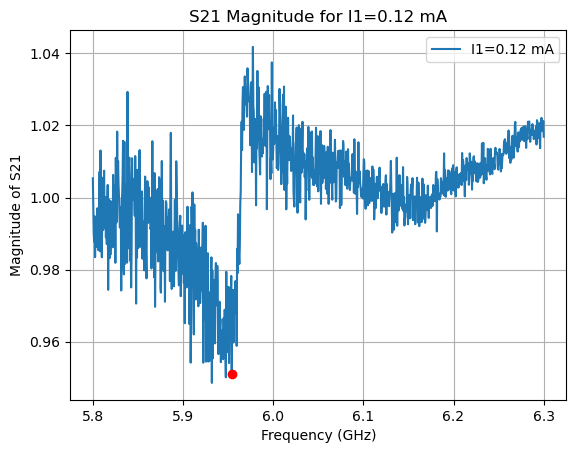

I1=0.24 mA: f0=5959500000.000000 Hz, i=52


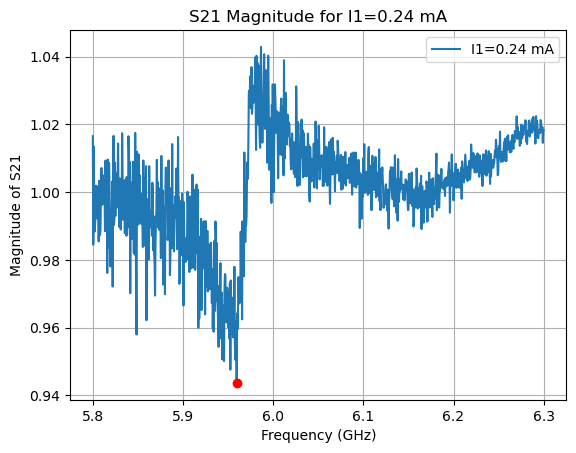

I1=0.36 mA: f0=5963000000.000000 Hz, i=53


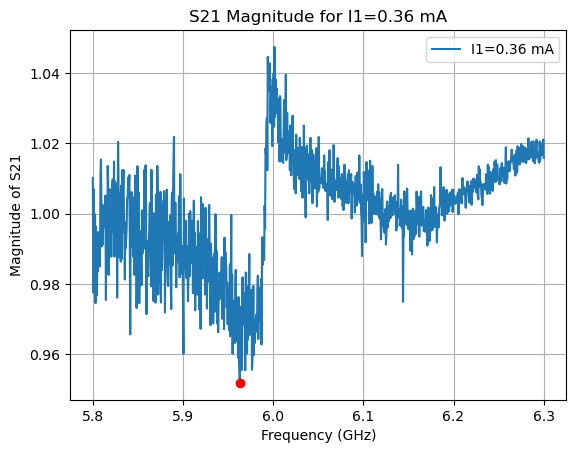

I1=0.48 mA: f0=5982500000.000000 Hz, i=54


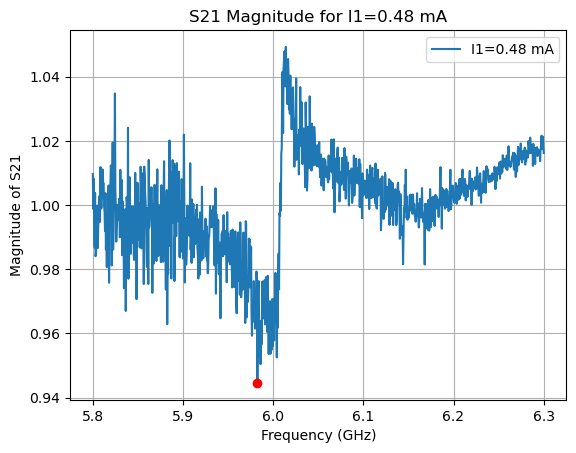

I1=0.6 mA: f0=6004500000.000000 Hz, i=55


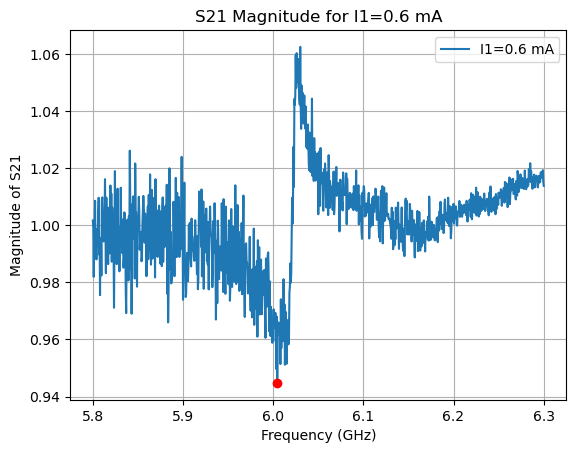

I1=0.72 mA: f0=6020000000.000000 Hz, i=56


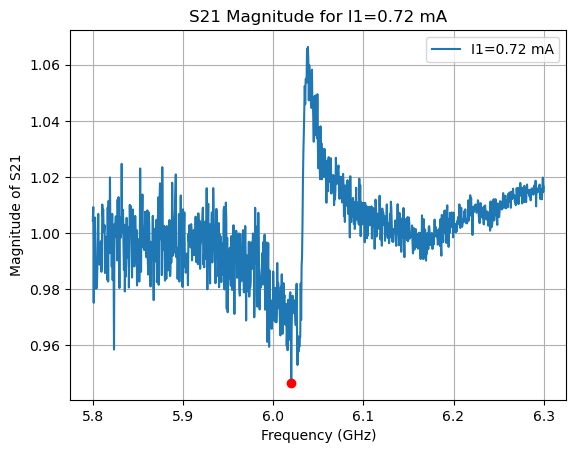

I1=0.84 mA: f0=6029000000.000000 Hz, i=57


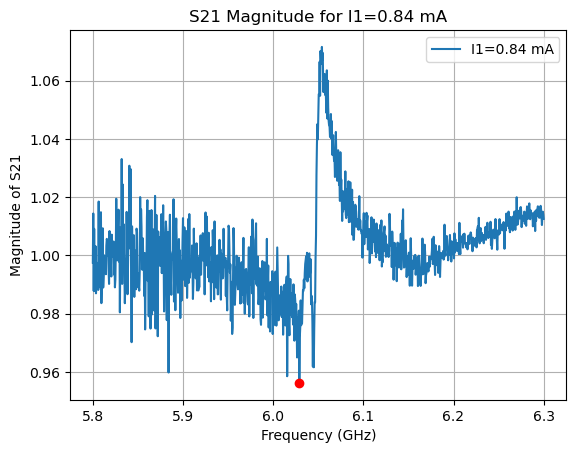

I1=0.96 mA: f0=6068500000.000000 Hz, i=58


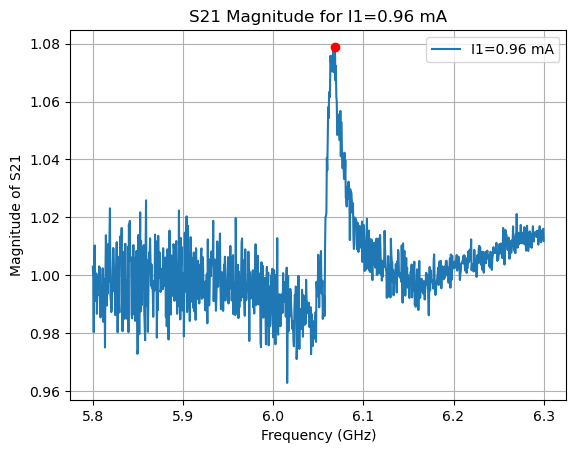

I1=1.08 mA: f0=6077500000.000000 Hz, i=59


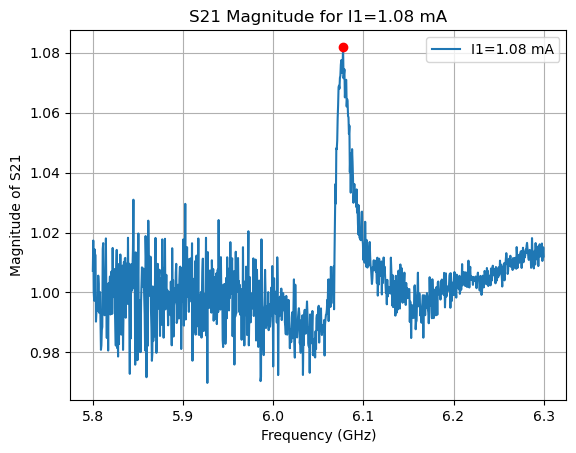

I1=1.2 mA: f0=6086500000.000000 Hz, i=60


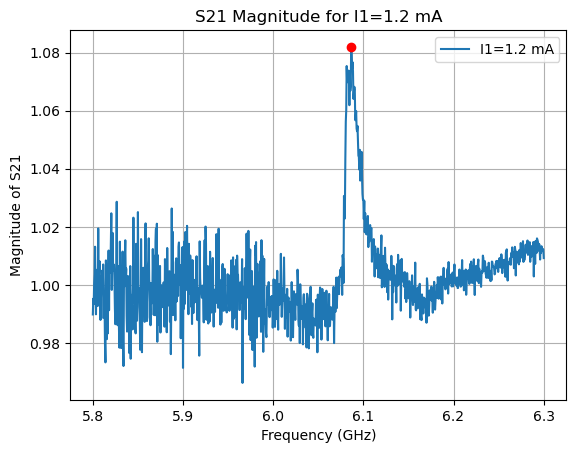

I1=1.32 mA: f0=6097000000.000000 Hz, i=61


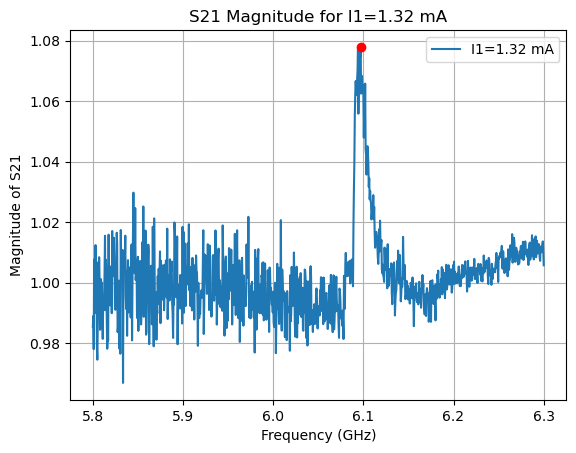

I1=1.44 mA: f0=6104500000.000000 Hz, i=62


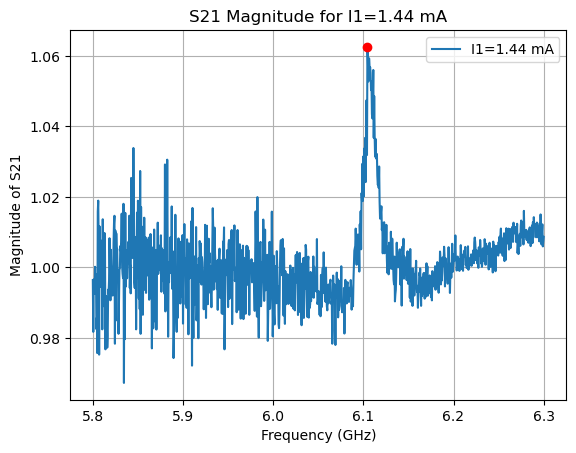

I1=1.56 mA: f0=6118500000.000000 Hz, i=63


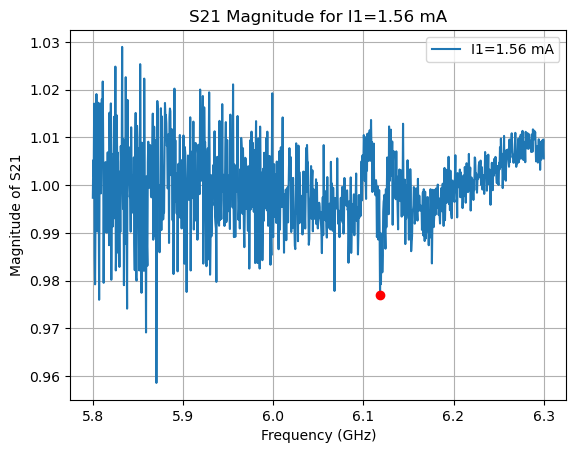

I1=1.68 mA: f0=6135000000.000000 Hz, i=64


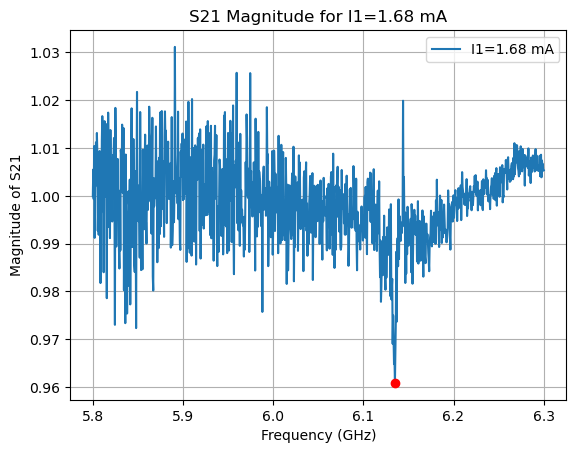

In [34]:
for i in range(39, 65, 1):
    S21_mag = np.abs(S21_Complex_full[:, i])

    plt.figure()
    line, = plt.plot(Freq/1e9, S21_mag, label=f'I1={I1_full[i]:.3g} mA')

    # Mark f0_guess on the curve
    f0 = f0_guess[i]  # Hz
    idx = np.argmin(np.abs(Freq - f0))  # nearest frequency index
    plt.plot(Freq[idx]/1e9, S21_mag[idx], 'o', color='r', markersize=6)

    print(f"I1={I1_full[i]:.3g} mA: f0={f0:.6f} Hz, i={i}")
    plt.xlabel('Frequency (GHz)')
    plt.ylabel('Magnitude of S21')
    plt.title(f'S21 Magnitude for I1={I1_full[i]:.3g} mA')
    plt.grid()
    plt.legend()
    plt.show()




In [8]:
fit_results_dict = {}
ports_dict = {}   # optional, if you want to re-plot a specific trace later without refitting
# window_halfwidth = 199e6 
# for i in range(40,43,1):
#     f0_guess[i] = f0_guess[44]
# for i in range(58,63,1):
#     f0_guess[i] = f0_guess[57]
# for i in range(S21_Complex_full.shape[1]):
#     if i  > 39 and i <  66:
#         window_halfwidth = 200e6
#     # elif i > 56 and i <  66:
#     #     window_halfwidth = 10e6
#     else:
#         window_halfwidth = 100e6

#     lower_bound = f0_guess[i] - window_halfwidth
#     upper_bound = f0_guess[i] + window_halfwidth
#     mask = (Freq >= lower_bound) & (Freq <= upper_bound)
#     f_sub = Freq[mask]
#     s_sub = S21_Complex_full[mask, i]

#     port_i = circuit.notch_port(f_sub, s_sub)
#     try:
#         port_i.autofit(electric_delay=0, fr_guess=f0_guess[i], Ql_guess=500)
#         fit_results_dict[i] = port_i.fitresults
#         ports_dict[i] = port_i
#     except Exception as e:
#         print(f"I1={I1_full[i]:.3g} mA: fit failed ({e})")
#         fit_results_dict[i] = None

last_good_Ql = 300
for i in range(S21_Complex_full.shape[1]):
    if i  > 39 and i <  66:
        window_halfwidth = 100e6
    # elif i > 56 and i <  66:
    #     window_halfwidth = 10e6
    else:
        window_halfwidth = 200e6

    lower_bound = f0_guess[i] - window_halfwidth
    upper_bound = f0_guess[i] + window_halfwidth
    mask = (Freq >= lower_bound) & (Freq <= upper_bound)
    f_sub = Freq[mask]
    s_sub = S21_Complex_full[mask, i]
    port_i = circuit.notch_port(f_sub, s_sub)
    best = None
    for Ql_try in (last_good_Ql, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000):
        try:
            p = circuit.notch_port(f_sub, s_sub)
            p.autofit(electric_delay=0, fr_guess=f0_guess[i], Ql_guess=Ql_try)
            fr, Ql = p.fitresults["fr"], p.fitresults["Ql"]
            ok = (Ql < 1.1e3) and (abs(fr - f0_guess[i]) < 50e6)
            if ok:
                resid = np.mean(np.abs(p.z_data_sim_norm - p.z_data)**2)  # or compare in the cropped region
                if best is None or resid < best[0]:
                    best = (resid, p)
        except Exception:
            pass
    if best is not None:
        ports_dict[i] = best[1]
        fit_results_dict[i] = best[1].fitresults
        last_good_Ql = best[1].fitresults["Ql"]
    else:
        fit_results_dict[i] = None   # flag for manual inspection

# now this actually compares two different fits:
# print(20, fit_results_dict[20])
# print(21, fit_results_dict[21])
# print(22, fit_results_dict[22]) 

C:\Users\chowdhf4\AppData\Roaming\Python\Python312\site-packages\resonator_tools\circlefit.py:130: RuntimeWarning: Number of calls to function has reached maxfev = 600.
  p_final = spopt.leastsq(
C:\Users\chowdhf4\AppData\Roaming\Python\Python312\site-packages\resonator_tools\circuit.py:685: RuntimeWarning: invalid value encountered in sqrt
  errors = np.sqrt(np.diagonal(cov))
C:\Users\chowdhf4\AppData\Roaming\Python\Python312\site-packages\resonator_tools\circlefit.py:157: RuntimeWarning: Number of calls to function has reached maxfev = 800.
  p_final = spopt.leastsq(
C:\Users\chowdhf4\AppData\Roaming\Python\Python312\site-packages\resonator_tools\circlefit.py:121: RuntimeWarning: Number of calls to function has reached maxfev = 600.
  p_final = spopt.leastsq(
C:\Users\chowdhf4\AppData\Roaming\Python\Python312\site-packages\resonator_tools\circuit.py:690: RuntimeWarning: invalid value encountered in sqrt
  Qi_no_corr_err = np.sqrt(


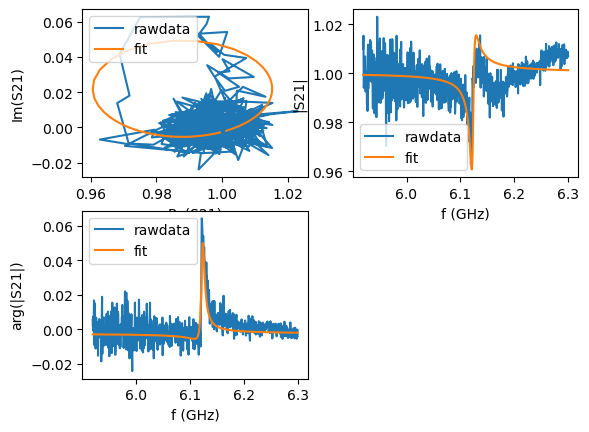

39
I1=-1.32 mA: f0=6123320843.386582 Hz, Ql=838


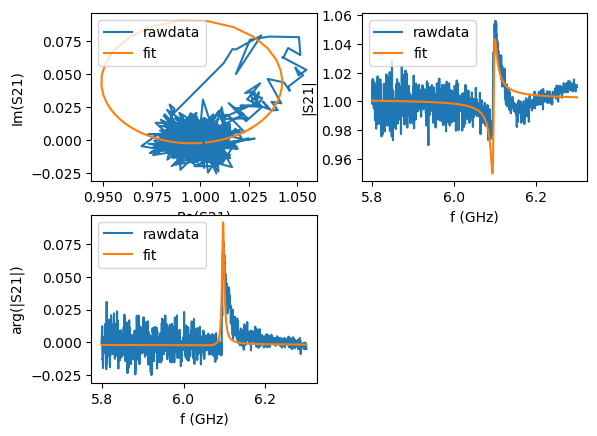

41
I1=-1.08 mA: f0=6096514693.595293 Hz, Ql=961


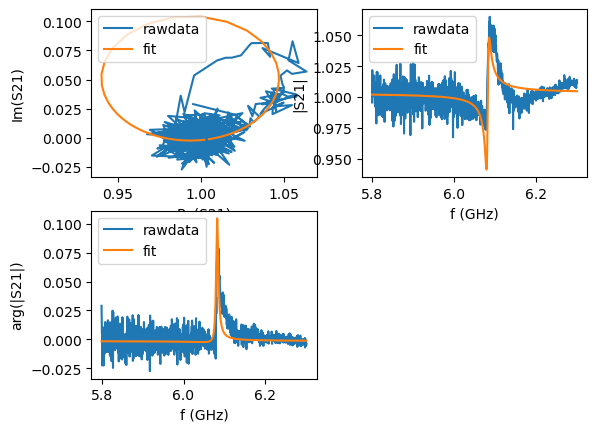

42
I1=-0.96 mA: f0=6081992021.742398 Hz, Ql=947


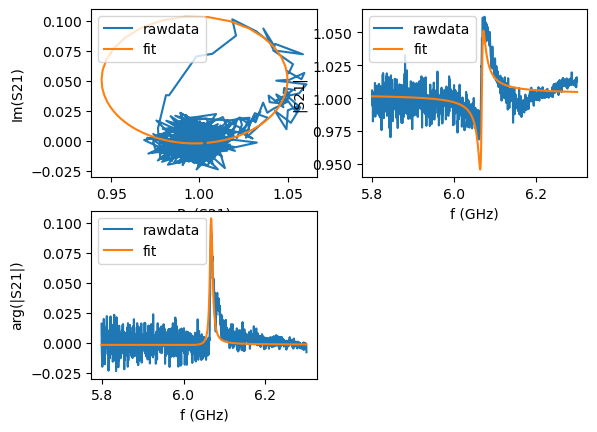

43
I1=-0.84 mA: f0=6067494822.089834 Hz, Ql=777


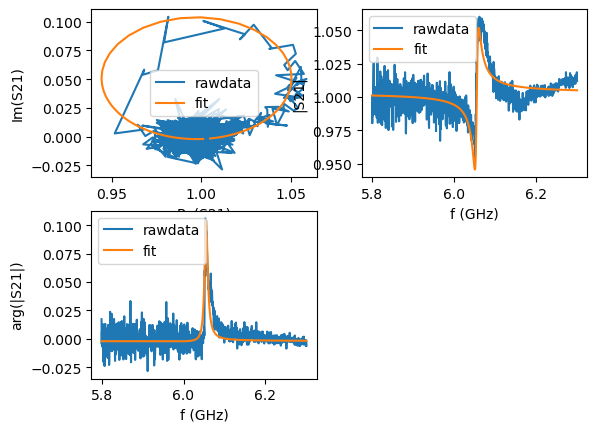

44
I1=-0.72 mA: f0=6055156866.978834 Hz, Ql=655


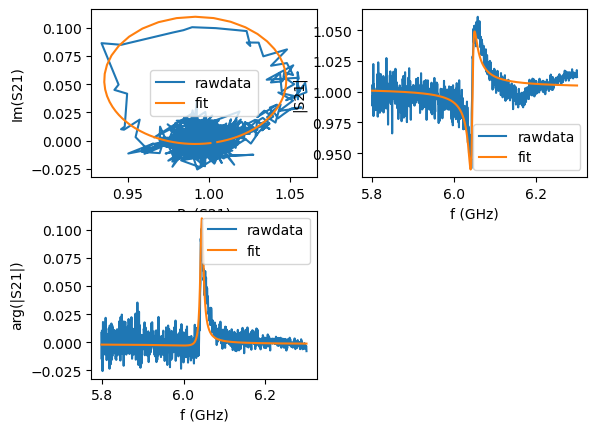

45
I1=-0.6 mA: f0=6044500711.804811 Hz, Ql=630


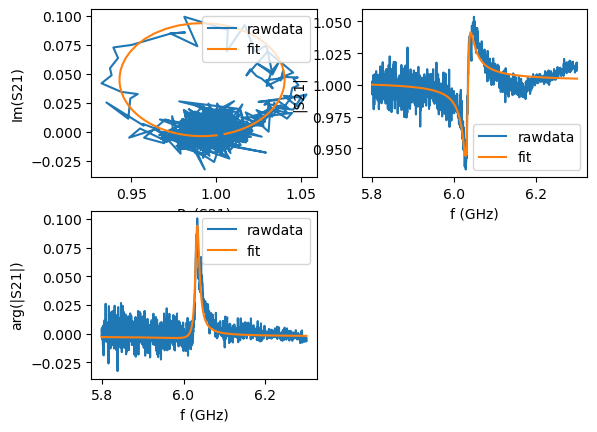

46
I1=-0.48 mA: f0=6033197160.925857 Hz, Ql=488


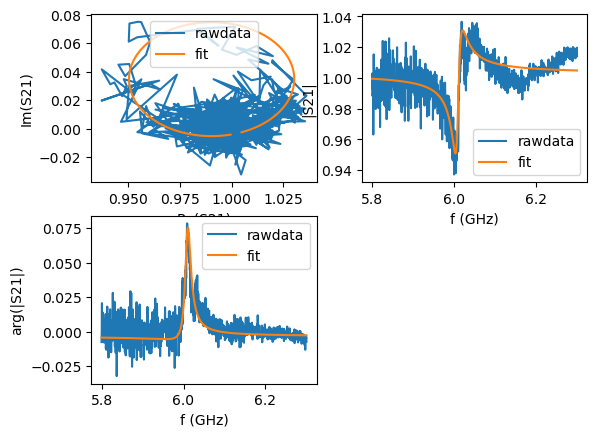

47
I1=-0.36 mA: f0=6009741933.909184 Hz, Ql=352


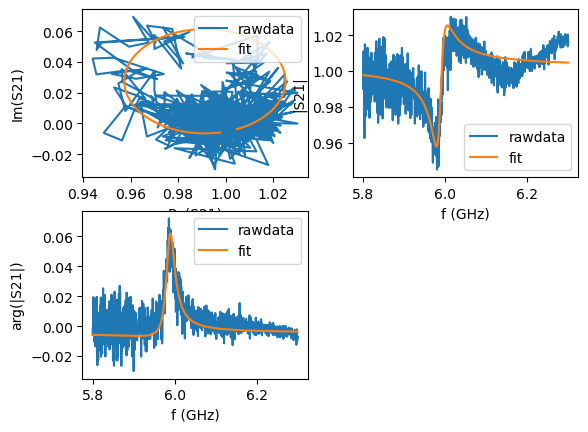

48
I1=-0.24 mA: f0=5988052859.278023 Hz, Ql=235


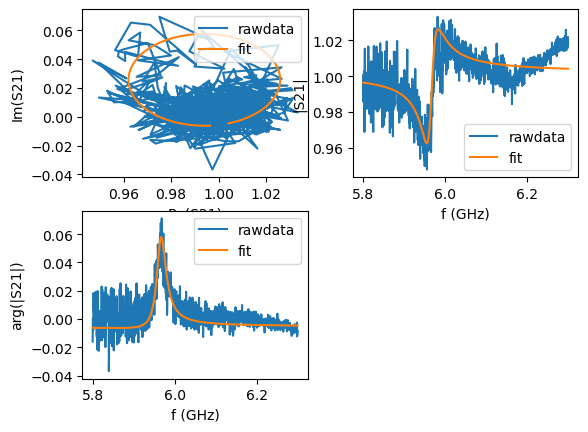

49
I1=-0.12 mA: f0=5966097821.661287 Hz, Ql=217


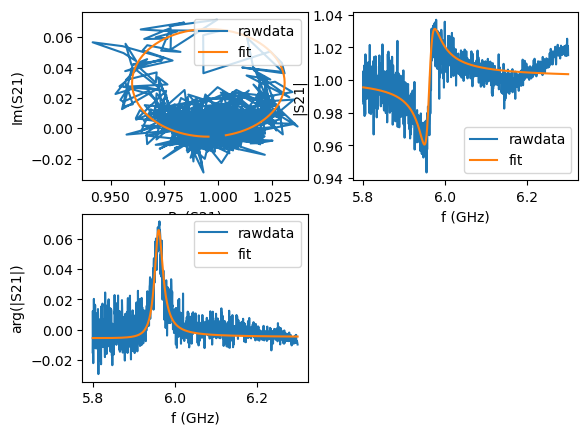

50
I1=0 mA: f0=5960429939.538232 Hz, Ql=238


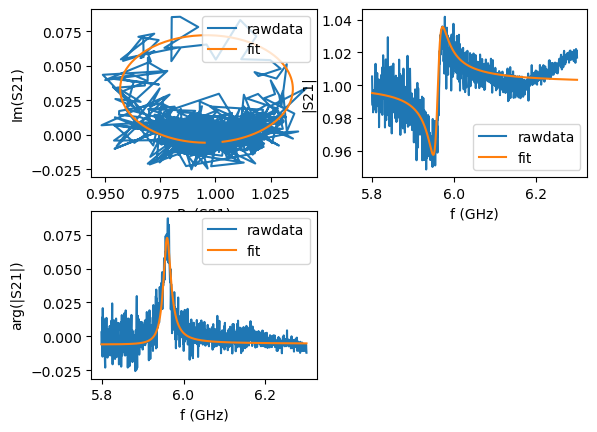

51
I1=0.12 mA: f0=5959672264.944089 Hz, Ql=263


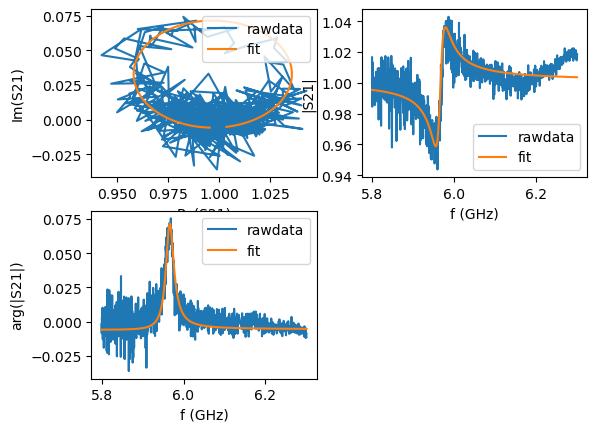

52
I1=0.24 mA: f0=5966354752.193936 Hz, Ql=252


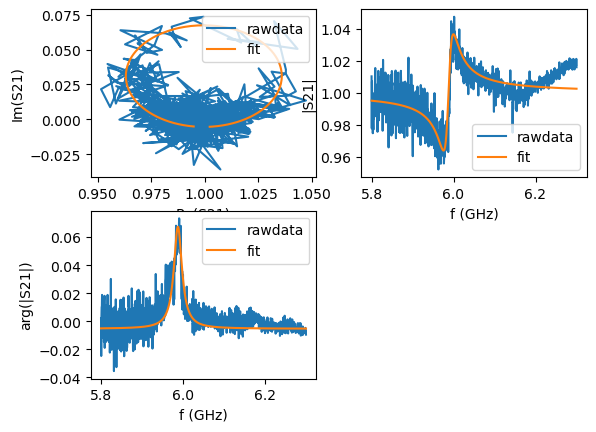

53
I1=0.36 mA: f0=5987991353.075705 Hz, Ql=248


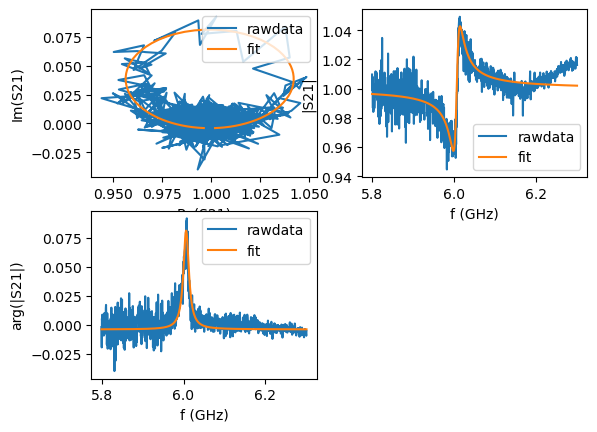

54
I1=0.48 mA: f0=6006699397.856711 Hz, Ql=370


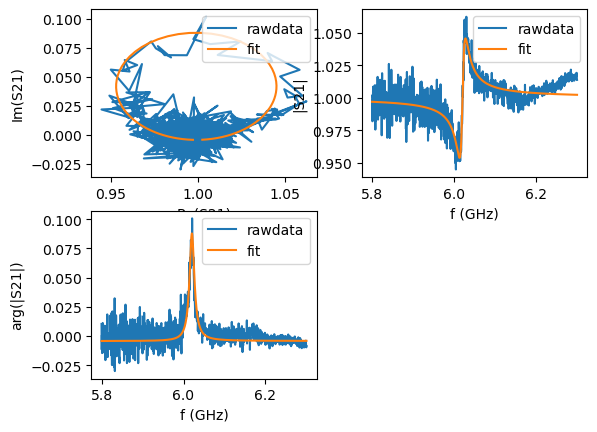

55
I1=0.6 mA: f0=6020733347.751063 Hz, Ql=418


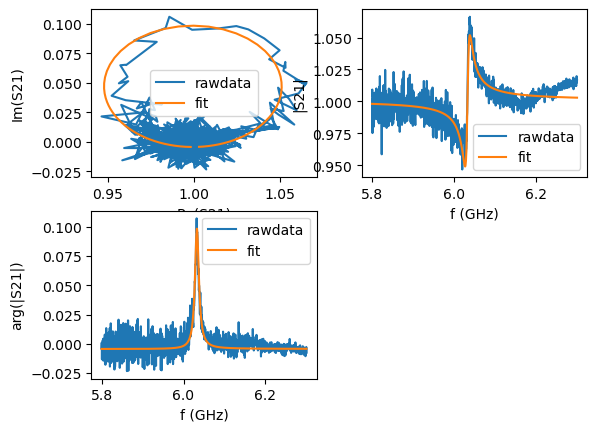

56
I1=0.72 mA: f0=6032900096.151199 Hz, Ql=517


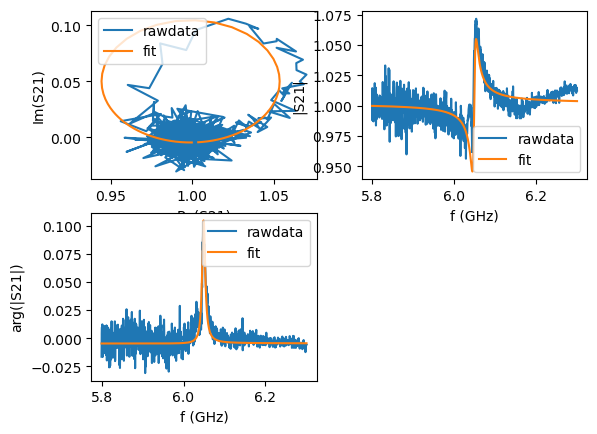

57
I1=0.84 mA: f0=6049272313.462605 Hz, Ql=672


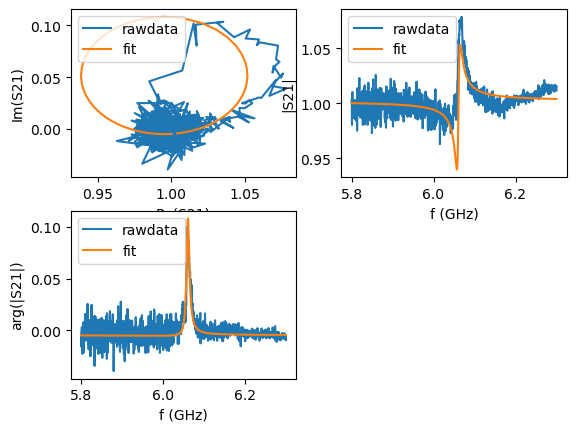

58
I1=0.96 mA: f0=6060733884.557819 Hz, Ql=720


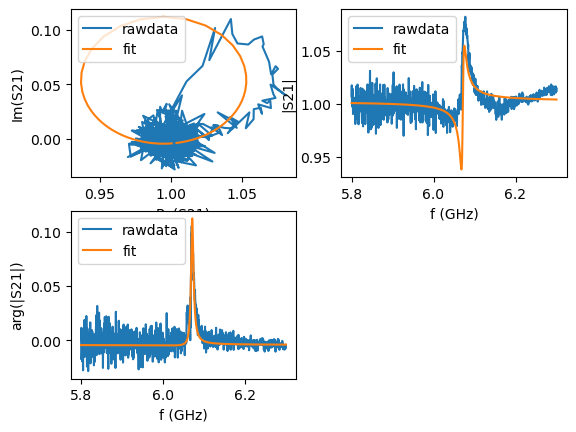

59
I1=1.08 mA: f0=6071283843.366808 Hz, Ql=852


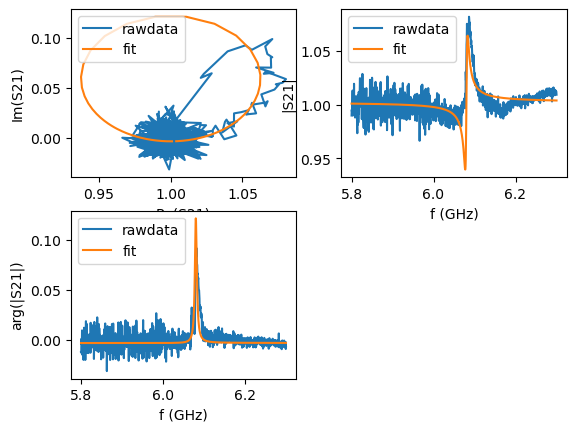

60
I1=1.2 mA: f0=6080199598.362003 Hz, Ql=1.06e+03


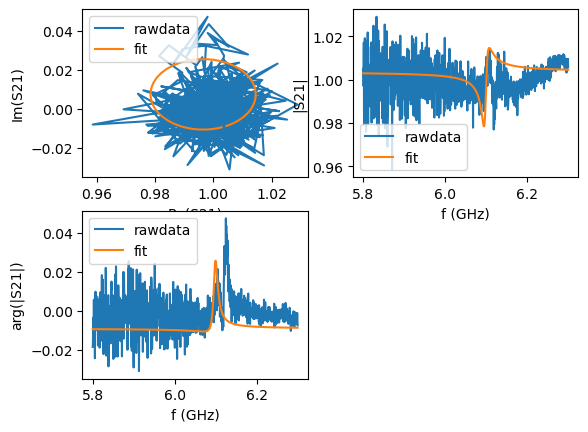

63
I1=1.56 mA: f0=6098627133.869967 Hz, Ql=507


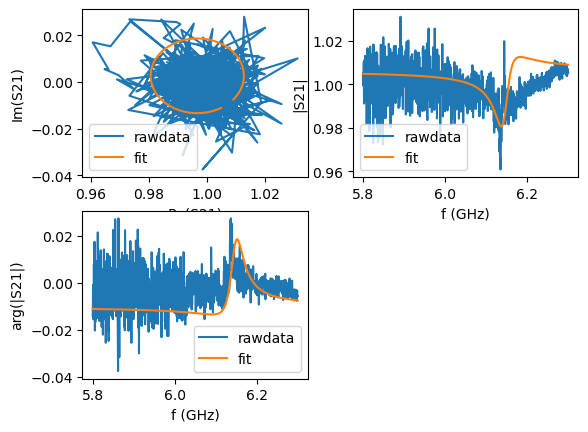

64
I1=1.68 mA: f0=6146286638.350000 Hz, Ql=164


In [78]:
for i in range(39, 66, 1):
        if fit_results_dict[i] is not None:
            ports_dict[i].plotall()
            print(i)
            print(f"I1={I1_full[i]:.3g} mA: f0={fit_results_dict[i]['fr']:.6f} Hz, Ql={fit_results_dict[i]['Ql']:.3g}")

In [9]:
import numpy as np

fr = np.full(len(fit_results_dict), np.nan)
Qi = np.full(len(fit_results_dict), np.nan)
Qc = np.full(len(fit_results_dict), np.nan)
Ql = np.full(len(fit_results_dict), np.nan)

for i, r in enumerate(fit_results_dict.values()):
    if r is None:
        continue
    fr[i] = r['fr']
    Qi[i] = r.get('Qi_dia_corr', r.get('Qi'))   # key names vary slightly by version — check port.fitresults.keys()
    Qc[i] = r.get('Qc_dia_corr', r.get('Qc'))
    Ql[i] = r['Ql']
    # Ql[61] = Ql[60]
    # Ql[43] = Ql[44]

In [80]:
np.where(np.isnan(Ql))

(array([40, 61, 62, 65], dtype=int64),)

In [18]:
for i in [0, 20]:
    r = fit_results_dict[i]
    print(i, {k: r[k] for k in ('fr','fr_err','Ql','Ql_err','phi0','phi0_err','theta0','chi_square')})

0 {'fr': 6215704744.005655, 'fr_err': 323754.57225095714, 'Ql': 275.24561702864736, 'Ql_err': 8.294005280983392, 'phi0': 1.4959776827822582, 'phi0_err': 0.02248236029196922, 'theta0': -1.645614970807535, 'chi_square': 4.9270018279553165e-05}
20 {'fr': 6187754524.395086, 'fr_err': 288969.3128330758, 'Ql': 451.6985773804432, 'Ql_err': 18.06233659290287, 'phi0': 1.2599877699403117, 'phi0_err': 0.03263289589678099, 'theta0': -1.8816048836494819, 'chi_square': 4.6921106405837056e-05}


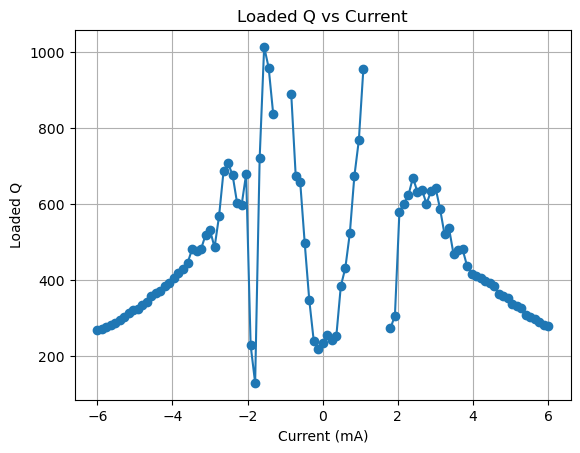

In [10]:
plt.plot(I1_full, Ql, 'o-')
# plt.plot(I1_full[43:58], Ql[43:58], 'o-')
# plt.plot(I1_full[56:57], Ql[56:57], 'o-')
#plt.plot(I1_full[62:100], Ql[62:100], 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('Loaded Q')
plt.title('Loaded Q vs Current')
plt.grid(True)
plt.show()

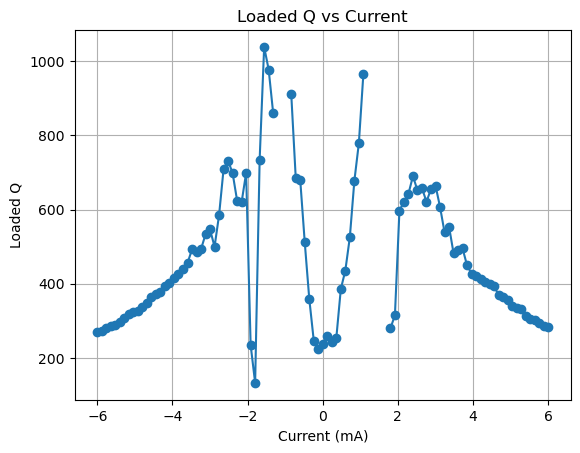

In [11]:
plt.plot(I1_full, Qi, 'o-')
# plt.plot(I1_full[43:58], Qi[43:58], 'o-')
# # plt.plot(I1_full[56:57], Ql[56:57], 'o-')
# plt.plot(I1_full[65:100], Qi[65:100], 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('Loaded Q')
plt.title('Loaded Q vs Current')
plt.grid(True)
plt.show()

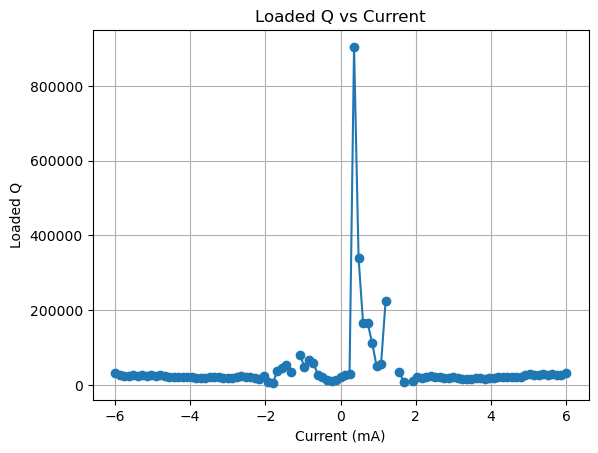

array([ 31491.31202274,  27800.64049368,  24184.51717363,  24563.86166224,
        25891.25472338,  24012.68127734,  26976.6108353 ,  23897.08919782,
        26165.80176202,  24610.45818198,  26445.19545285,  23992.64515749,
        22376.44541184,  21246.83047986,  21148.76117427,  22510.87706391,
        20309.90119011,  21460.96696659,  19233.22741108,  18755.22553257,
        18525.05534395,  21057.72519502,  21248.25972575,  21148.87802056,
        19181.44607568,  19763.57668785,  18176.55796487,  20971.59202397,
        23488.01669934,  22255.34123113,  22011.56794736,  18062.51591891,
        16941.79318862,  24878.75914229,   8528.34573466,   5437.75989927,
        37641.10915546,  44205.40481021,  53656.04648695,  33754.06255666,
                   nan,  80353.95605708,  48541.95426235,  67188.01546954,
        57600.47408819,  27131.27014732,  21855.65093716,  14202.76816423,
        10674.11659757,  13935.20003277,  20726.83541505,  26773.85839318,
        30090.53758526, 9

In [65]:
plt.plot(I1_full, Qc, 'o-')
# plt.plot(I1_full[43:58], Qc[43:58], 'o-')
# # plt.plot(I1_full[56:57], Ql[56:57], 'o-')
# plt.plot(I1_full[65:100], Qc[65:100], 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('Loaded Q')
plt.title('Loaded Q vs Current')
plt.grid(True)
plt.show()
Qc

In [51]:
"""
Bounded, warm-started complex fit for notch resonances with a mismatch background.
Replaces resonator_tools' autofit for the hard traces (low SNR, Fano-like lineshape).

Model:  S21(f) = B(f) * [ 1 - (Ql/|Qc|) e^{i phi} / (1 + 2 i Ql (f/fr - 1)) ]
        B(f)   = complex quadratic in x = (f - f0_guess)/half   (absorbs ripple, residual delay)

Why this doesn't collapse like the circle fit:
  * fr is bounded to f0_guess +- tol, Ql to [Ql_min, Ql_max]  -> no Ql = 1e5 spike solutions
  * the background is fitted jointly instead of assumed flat   -> no need to pre-normalise
  * every trace is compared with a no-resonance model          -> weak traces are FLAGGED
    (significance) instead of returning garbage or NaN
"""
import numpy as np
from scipy.optimize import least_squares


def _bg(b, x):
    return (b[0] + 1j*b[1]) + (b[2] + 1j*b[3])*x + (b[4] + 1j*b[5])*x**2


def _model(p, f, f0g, half):
    dfr, lnQl, lnQc, phi = p[:4]
    fr = f0g + dfr*1e6
    Ql, Qc = np.exp(lnQl), np.exp(lnQc)
    res = 1 - (Ql/Qc)*np.exp(1j*phi)/(1 + 2j*Ql*(f/fr - 1))
    return _bg(p[4:10], (f - f0g)/half) * res


def _flat_cost(f, s, f0g, half):
    """best complex-quadratic background with no resonance (linear LSQ)"""
    x = (f - f0g)/half
    A = np.vstack([np.ones_like(x), x, x**2]).T
    coef, *_ = np.linalg.lstsq(A, s, rcond=None)
    return np.sum(np.abs(s - A @ coef)**2)


def fit_trace(f, s, f0g, prev=None, tol=8e6, half=80e6,
              Ql_bounds=(50, 1.2e3), Qc_bounds=(50, 1e7),
              Ql_starts=(100, 200, 300, 400, 500, 600, 700, 800, 900, 1000), phi_starts=(-1.5, 0.0, 1.5)):
    """
    f, s   : full frequency axis and complex S21 of ONE trace
    f0g    : your f0 guess (Hz)
    prev   : dict returned by the previous good fit (warm start), or None
    tol    : max |fr - f0g| allowed (Hz)
    half   : half-width of the fitted window (Hz)
    """
    m = np.abs(f - f0g) <= half
    f, s = f[m], s[m]

    lo = [-tol/1e6, np.log(Ql_bounds[0]), np.log(Qc_bounds[0]), -np.pi] + [-np.inf]*6
    hi = [+tol/1e6, np.log(Ql_bounds[1]), np.log(Qc_bounds[1]), +np.pi] + [+np.inf]*6

    def resid(p):
        r = _model(p, f, f0g, half) - s
        return np.concatenate([r.real, r.imag])

    b0 = np.median(s)
    starts = []
    Ql_list = list(Ql_starts)
    phi_list = list(phi_starts)
    if prev is not None:
        Ql_list = [prev["Ql"]] + Ql_list
        phi_list = [prev["phi"]] + phi_list
    for Ql0 in Ql_list:
        for phi0 in phi_list:
            Qc0 = (prev["Qc"] if prev is not None else 10*Ql0)
            Qc0 = np.clip(Qc0, *Qc_bounds)
            starts.append([0.0, np.log(Ql0), np.log(Qc0), phi0, b0.real, b0.imag, 0, 0, 0, 0])

    best = None
    for p0 in starts:
        try:
            sol = least_squares(resid, p0, bounds=(lo, hi), method="trf",
                                x_scale=[1, 1, 1, 1, 1, 1, .1, .1, .1, .1], max_nfev=400)
        except Exception:
            continue
        if best is None or sol.cost < best.cost:
            best = sol
    if best is None:
        return None

    p = best.x
    n = 2*f.size
    sigma2 = 2*best.cost/(n - 10)                      # per-quadrature noise variance
    sig = (_flat_cost(f, s, f0g, half) - 2*best.cost)/ (sigma2*1.0)   # ~ delta chi^2 vs "no resonance"
    try:
        cov = np.linalg.inv(best.jac.T @ best.jac) * sigma2
        err = np.sqrt(np.diag(cov))
    except np.linalg.LinAlgError:
        err = np.full(10, np.nan)

    Ql, Qc = np.exp(p[1]), np.exp(p[2])
    phi = p[3]
    inv_Qi = 1/Ql - np.cos(phi)/Qc                     # Probst convention: 1/Qc_real = cos(phi)/|Qc|
    out = dict(
        fr=f0g + p[0]*1e6, fr_err=err[0]*1e6, Ql=Ql, Qc=Qc, phi=phi,
        Qi=(1/inv_Qi if inv_Qi > 0 else np.nan),
        delta_chi2=sig, rms=np.sqrt(sigma2),
        at_bound=bool(abs(p[0]) > 0.98*tol/1e6 or Ql > 0.98*Ql_bounds[1] or Ql < 1.02*Ql_bounds[0]),
        params=p, f=f, s=s, f0g=f0g, half=half,
    )
    return out


def fit_all(Freq, S21, f0_guess, min_signif=30.0, **kw):
    """Loop over traces (columns of S21), warm-starting from the last trusted fit."""
    results, prev = [], None
    for i in range(S21.shape[1]):
        r = fit_trace(Freq, S21[:, i], f0_guess[i], prev=prev, **kw)
        if r is not None:
            r["trusted"] = (r["delta_chi2"] > min_signif) and (not r["at_bound"])
            if r["trusted"]:
                prev = r
        results.append(r)
    return results


def plot_trace(r, title=""):
    import matplotlib.pyplot as plt
    f, s = r["f"], r["s"]
    m = _model(r["params"], f, r["f0g"], r["half"])
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    ax[0].plot(s.real, s.imag, ".", ms=2, alpha=.5); ax[0].plot(m.real, m.imag, "r"); ax[0].set_aspect("equal")
    ax[0].set_xlabel("Re S21"); ax[0].set_ylabel("Im S21")
    ax[1].plot(f/1e9, np.abs(s), lw=.6); ax[1].plot(f/1e9, np.abs(m), "r"); ax[1].set_xlabel("f (GHz)"); ax[1].set_ylabel("|S21|")
    ax[2].plot(f/1e9, np.unwrap(np.angle(s)), lw=.6); ax[2].plot(f/1e9, np.unwrap(np.angle(m)), "r"); ax[2].set_xlabel("f (GHz)"); ax[2].set_ylabel("arg S21")
    fig.suptitle(f"{title}  fr={r['fr']/1e9:.5f} GHz  Ql={r['Ql']:.0f}  dchi2={r['delta_chi2']:.0f}  trusted={r.get('trusted')}")
    plt.tight_layout(); plt.show()

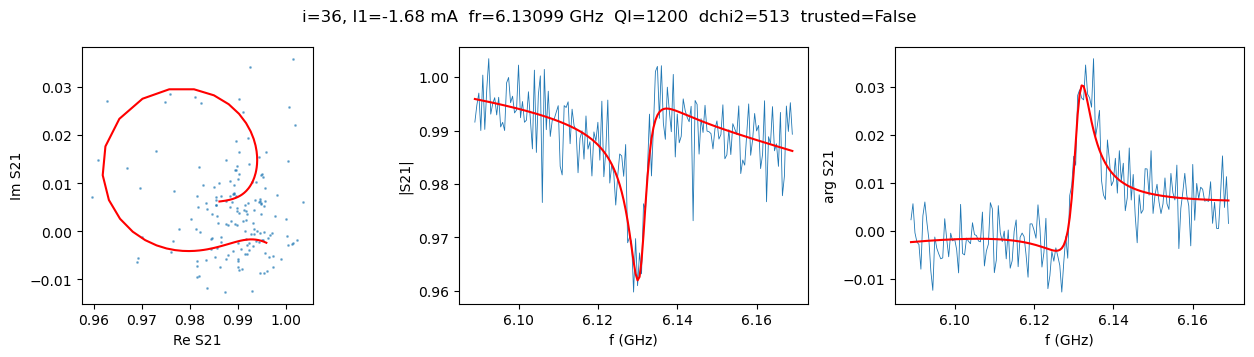

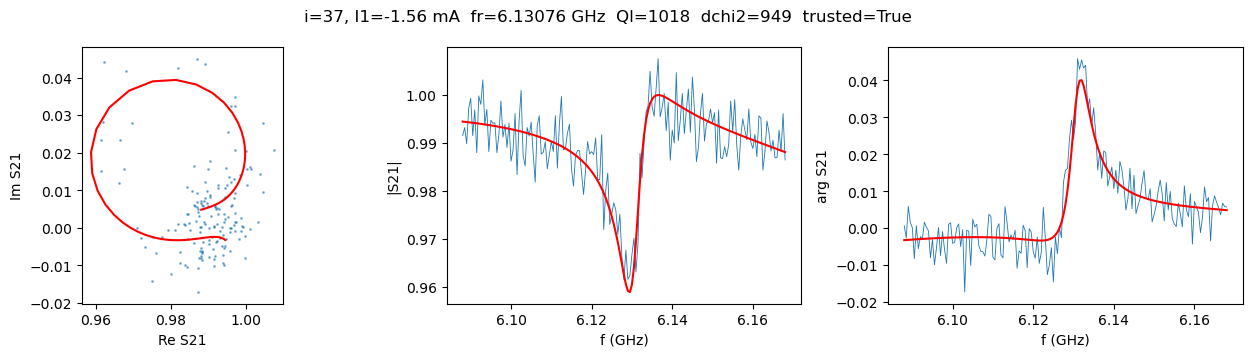

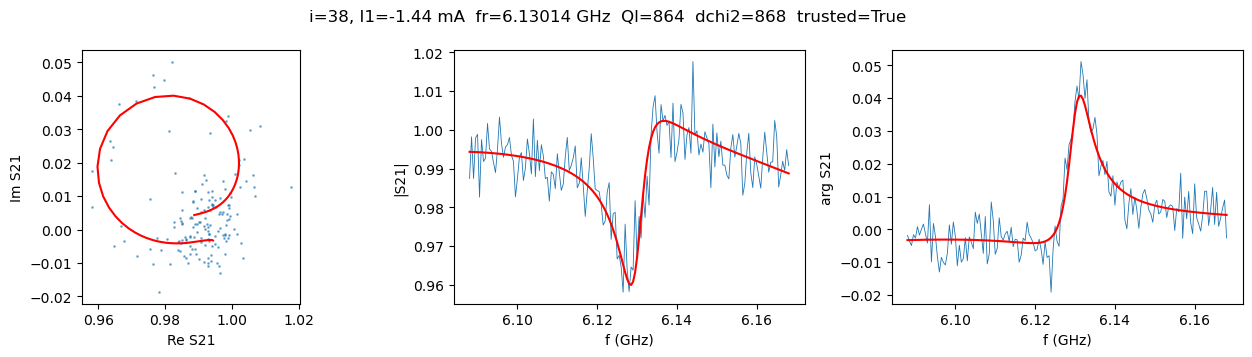

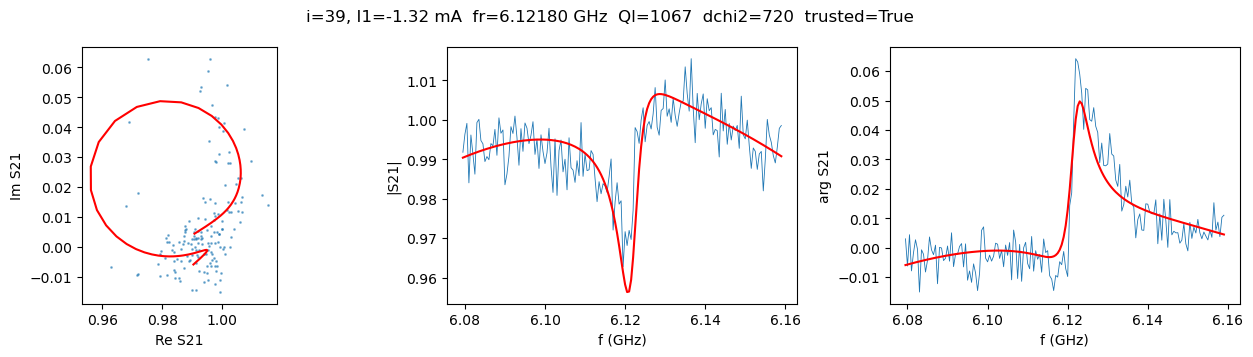

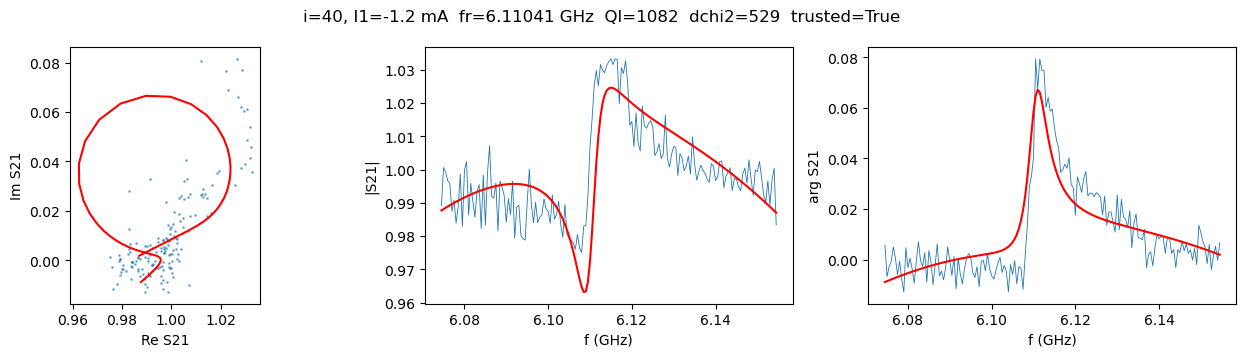

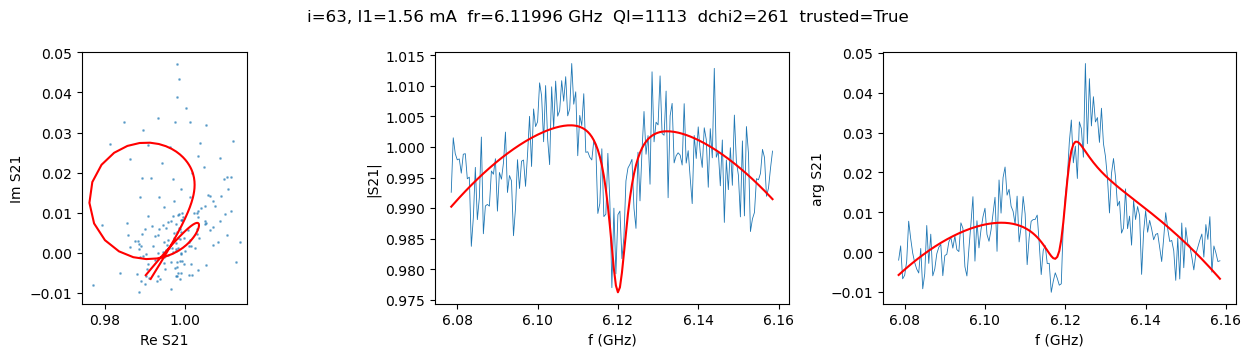

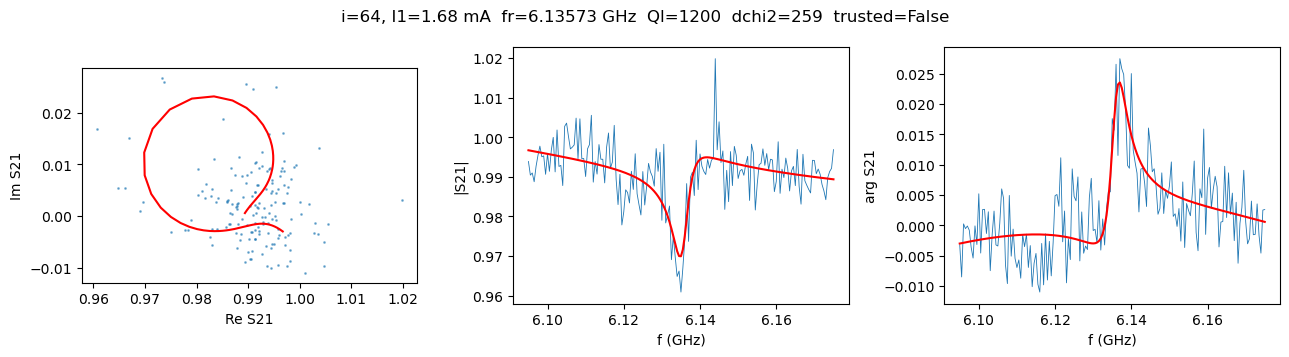

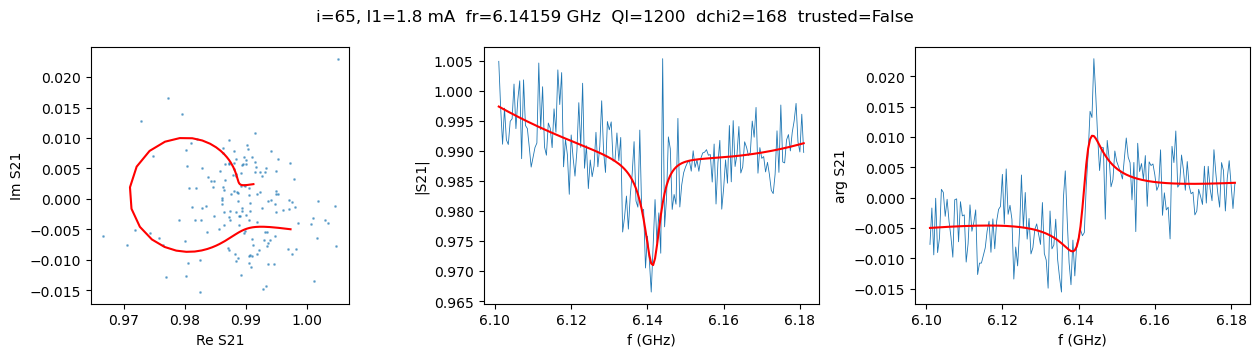

In [53]:
res_Qs = fit_all(Freq, S21_Complex_full, f0_guess, tol=8e6, half=40e6, min_signif=30)

for i in (36, 37, 38, 39, 40, 63, 64, 65):
    if res_Qs[i] is not None:
        plot_trace(res_Qs[i], title=f"i={i}, I1={I1_full[i]:.3g} mA")

In [54]:
n = len(res_Qs)
keys = ["fr", "Ql", "Qc", "Qi", "fr_err", "delta_chi2"]
out = {k: np.full(n, np.nan) for k in keys}
trusted = np.zeros(n, dtype=bool)

for i, r in enumerate(res_Qs):
    if r is None:
        continue
    for k in keys:
        out[k][i] = r[k]
    trusted[i] = r["trusted"]

Ql_v2 = out["Ql"]
Qc_v2  = out["Qc"]
Qi_v2 = out["Qi"]
fr_v2 = out["fr"]

In [49]:
np.argwhere(Ql_v2 > 800)

array([[36],
       [37],
       [38],
       [39],
       [40],
       [63],
       [64],
       [65]], dtype=int64)

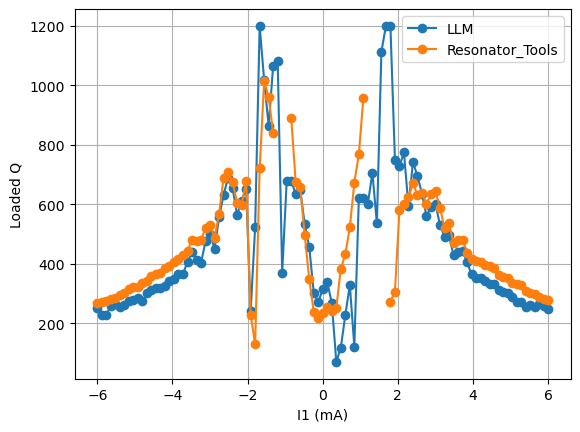

In [55]:
plt.plot(I1_full, Ql_v2, 'o-', label = 'LLM')
plt.plot(I1_full, Ql, '-o', label = 'Resonator_Tools')
# plt.plot(I1_full[~trusted], Ql[~trusted], 'x', color='r', label='flagged')
plt.xlabel('I1 (mA)')
plt.ylabel('Loaded Q')
plt.yscale('linear')   # optional, Ql spans orders of magnitude here
plt.legend()
plt.grid(True)
plt.show()

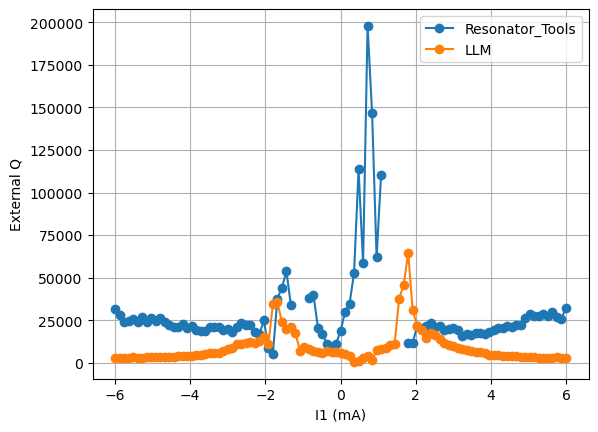

In [23]:
plt.plot(I1_full, Qc, 'o-', label = 'Resonator_Tools')
plt.plot(I1_full, Qc_v2, '-o', label = 'LLM')
# plt.plot(I1_full[~trusted], Ql[~trusted], 'x', color='r', label='flagged')
plt.xlabel('I1 (mA)')
plt.ylabel('External Q')
plt.yscale('linear')   # optional, Ql spans orders of magnitude here
plt.legend()
plt.grid(True)
plt.show()

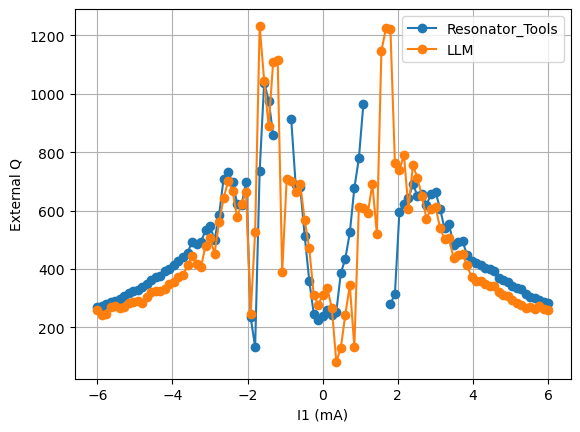

In [24]:
plt.plot(I1_full, Qi, 'o-', label = 'Resonator_Tools')
plt.plot(I1_full, Qi_v2, '-o', label = 'LLM')
# plt.plot(I1_full[~trusted], Ql[~trusted], 'x', color='r', label='flagged')
plt.xlabel('I1 (mA)')
plt.ylabel('External Q')
plt.yscale('linear')   # optional, Ql spans orders of magnitude here
plt.legend()
plt.grid(True)
plt.show()

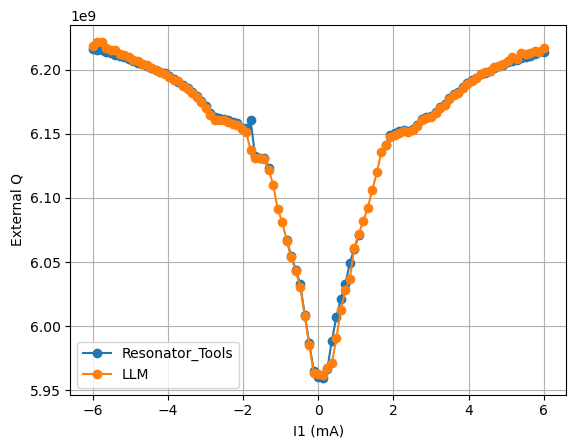

In [26]:
plt.plot(I1_full, fr, 'o-', label = 'Resonator_Tools')
plt.plot(I1_full, fr_v2, '-o', label = 'LLM')
# plt.plot(I1_full[~trusted], Ql[~trusted], 'x', color='r', label='flagged')
plt.xlabel('I1 (mA)')
plt.ylabel('External Q')
plt.yscale('linear')   # optional, Ql spans orders of magnitude here
plt.legend()
plt.grid(True)
plt.show()

In [27]:
# Data to use is; Qi_v2, fr_v2
from scipy.special import ellipk
from scipy.signal import find_peaks, peak_widths
from scipy.constants import mu_0, epsilon_0
from scipy.optimize import root, curve_fit
from functools import partial
from scipy.io import loadmat
from scipy.optimize import least_squares

In [28]:
def del_sol(delta, a, phi_ext_val):
    
    lhs = delta + a * np.sin(delta)
    
    return lhs - phi_ext_val


# calculates the impedance of the coupling capacitor to the transmission line (not shown in the setup)
def c_cap(c_c, w):
    return np.array([[1,1/(1j*c_c*w)],[0,1]])

# calculates the impedance of the resonator
def tline(Z0, beta, L):
    return np.array([[np.cos(beta*L),1j*Z0*np.sin(beta*L)],[1j*(1/Z0)*np.sin(beta*L),np.cos(beta*L)]])


def Z_L(L_01, L_02, L_T, d, w, R):
    # R_n = (L_T*np.pi**2*delta_0)/(elec_c*phi_0)
    ZL01 = 1j*w*L_01
    ZL02 = 1j*w*L_02
    ZLT = 1j*w*L_T/np.cos(d)
    # ZCT = 1/(1j*w*CT)
    Z_squid = ZLT #(1/ZLT + 1/ZCT + 1/R_n)**(-1)
    ZL02R = (1/ZL02 + 1/R)**(-1)
    ZSQUID = (1/ZL01 + 1/(Z_squid + ZL02R))**(-1)
    
    return ZSQUID

def Z_tot(ZL, Z0, beta, l, c_c, w):
    x = beta*l
    Z_c = 1/(1j*w*c_c)
    return (Z0*((ZL + 1j*Z0*np.tan(x))/(Z0 + 1j*ZL*np.tan(x)))) + Z_c

def branch(Z):
    return np.array([[1,0], [1/Z, 1]])
    
#calculates the ABCD matrix
def ABCD(M1, M2, M3):
    full_M = M1 @ M2 @ M3 
    
    return full_M
#Calculates the S21 parameter
def S21(A, B, C, D, Z0):
    return 2/(A + B/Z0 + C*Z0 + D)


def current_to_flux(I, M, o):
    return M*I + o


In [29]:
def solve_delta(phi_ext, a):
    phi_ext = np.asarray(phi_ext)
    delta = np.zeros_like(phi_ext, dtype=float)
    order = np.argsort(phi_ext)          # continuity in phi_ext, not array position
    d0 = 0.0
    for idx in order:
        sol = root(del_sol, d0, args=(a, phi_ext[idx]))
        delta[idx] = sol.x[0]
        d0 = sol.x[0]
    return delta

def S21_fit_func(X, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f, Z0=50):
    """
    X = (I, f): current (A) and frequency (Hz) arrays, same length (elementwise pairs).
    Fit params: L0 (=L01=L02), LT, L_l, C_l, C_c, R_j
    Fixed:      l_f (resonator length), M, O (current -> flux calibration)
    """
    I, f = X
    w = 2 * np.pi * f
    phi_ext = M * I + O #np.pi - 0.5 -0.25 - 0.25 - 0.25

    a = 2 * L0 / LT
    delta = solve_delta(phi_ext, a)

    beta = w * np.sqrt(L_l * C_l)
    ZL = Z_L(L0, L0, LT, delta, w, R_j)
    Ztot = Z_tot(ZL, Z0, beta, l_f, C_c, w)

    return 2 / (2 + Z0 / Ztot)

def S21_fit_mag_dB(X, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f):
    S21 = S21_fit_func(X, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f)
    return 20 * np.log10(np.abs(S21))

In [31]:
def calc_cpw_param_set(
    center_width: float, gap_width: float, substrate_r: float, metal_thickness: float
):
    a = center_width / 2
    b = center_width / 2 + gap_width
    d = metal_thickness / (2 * np.pi)

    u1 = (
        a
        + d / 2
        + 3 / 2 * np.log(2) * d
        - d / 2 * np.log(d / a)
        + d / 2 * np.log((b - a) / (a + b))
    )
    u2 = (
        b
        - d / 2
        - 3 / 2 * np.log(2) * d
        + d / 2 * np.log(d / a)
        + d / 2 * np.log((b - a) / (a + b))
    )
    k1 = u1 / u2
    k2 = np.sqrt(1 - k1**2)
    c = 2 * epsilon_0 * ellipk(k1) / ellipk(k2) * (1 + substrate_r)

    d = d/2
    u1 = a+d/2+3/2*np.log(2)*d-d/2*np.log(d/a)+d/2*np.log((b-a)/(a+b))
    u2 = b-d/2-3/2*np.log(2)*d+d/2*np.log(d/a)+d/2*np.log((b-a)/(a+b))
    k1 = u1/u2
    k2 = np.sqrt(1-k1**2)
    l = mu_0/4*ellipk(k2)/ellipk(k1)

    lambda_eff = 50e-9  # m, effective field penetration depth
    k = a/b
    g_ctr = 1/(4*a*ellipk(k)**2*(1-k)**2) * \
        (np.pi+np.log(4*np.pi*a/metal_thickness)-k*np.log((1+k)/(1-k)))
    g_gnd = 1/(4*a*ellipk(k)**2*(1-k)**2) * \
        (np.pi+np.log(4*np.pi*b/metal_thickness)-k*np.log((1+k)/(1-k)))
    g = g_ctr+g_gnd
    l_ki = g*mu_0*lambda_eff
    l_tot = l+l_ki

    return {'inductance': l_tot, 'capacitance': c}

def calc_target_length(target_frequency: float, cpw_param_set: dict):
    return 1e6 / (4 * target_frequency * np.sqrt(cpw_param_set['inductance'] * cpw_param_set['capacitance']))



def calc_target_frequency(target_length: float, cpw_param_set: dict):
    return 1e6 / (4 * target_length * np.sqrt(cpw_param_set['inductance'] * cpw_param_set['capacitance']))



resonator_widths = [7, 10, 7]
#################################3

res_cpw_param_set = calc_cpw_param_set(
    center_width= resonator_widths[1]*1e-6, 
    gap_width=resonator_widths[0]*1e-6, 
    substrate_r=11.6, 
    metal_thickness=200e-9
)
l = calc_target_length(7e9, res_cpw_param_set)
R_L = l/1e6
L_l = res_cpw_param_set['inductance']
C_l = res_cpw_param_set['capacitance']
R_L

0.004024914687959033

In [38]:
def lorentzian_dip_power(f, f0, Q_L, baseline, Q_e_inv):
    """
    Fit model for |S21|^2 in terms of Q factors directly.
    Q_e_inv = 1/Q_e (easier to fit as a free parameter)
    """
    depth_amplitude = Q_L * Q_e_inv          # = Q_L / Q_e
    lorentz = depth_amplitude / (1 + 4 * Q_L**2 * ((f - f0)/f0)**2)
    # |S21|^2 = baseline * |1 - lorentz|^2
    return baseline * (1 - lorentz)**2


# Drop-in replacement for calculate_q_factors in cell 26 (keep your lorentzian_dip_power as is).
# Default behaviour (plot=False) is identical to your current version.
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


def calculate_q_factors(freq, S21_vals, min_pts=2,
                        plot=False, n_plot=16, plot_idx=None, labels=None):
    """Same extraction/rejection logic as before.  With plot=True it also shows a grid of
    traces (all rejected ones first, remaining slots filled with evenly spaced accepted ones)
    so the Lorentzian fits can be judged by eye.  Rejected traces are still fitted for display
    (when possible), but their results are NOT returned.
      plot_idx : explicit list of trace indices to show (overrides the automatic choice)
      labels   : per-trace labels for the titles, e.g. the current array
    """
    n = S21_vals.shape[1]
    q_loaded, q_internal, q_external, f0_fits = (np.full(n, np.nan) for _ in range(4))
    df = freq[1] - freq[0]
    diag = {}

    for i in range(n):
        power = np.abs(S21_vals[:, i])**2
        d = diag[i] = dict(status='ok', k=None, base=None, half=None, below=None, p0=None, popt=None)
        k = np.argmin(power)
        d['k'] = k
        if k == 0 or k == len(freq) - 1:
            d['status'] = 'REJECTED: dip at window edge (no f0)'
            continue                                   # dip at window edge: no f0, no Q

        y0, y1, y2 = power[k-1], power[k], power[k+1]  # f0: parabolic interpolation, always available
        den = y0 - 2*y1 + y2
        f0_fits[i] = freq[k] + (0.5*(y0 - y2)/den*df if den != 0 else 0.0)

        base = power.max()
        half = base - (base - y1)/2
        below = np.where(power < half)[0]
        d.update(base=base, half=half, below=below)

        reason = None
        if len(below) < min_pts:
            reason = f'REJECTED: unresolved ({len(below)} pts below half-depth, need >= {min_pts})'
        elif len(below) > len(freq)//1.25:
            reason = f'REJECTED: too broad ({len(below)} pts below half-depth, max {len(freq)//1.25})'
        if reason is not None and not plot:
            continue                                   # unresolved or too broad: skip Q only

        df_guess = freq[below[-1]] - freq[below[0]] if len(below) > 1 else 0.0
        if df_guess <= 0:
            df_guess = 3*df                            # only reachable for rejected traces in plot mode
        QL0 = freq[k]/df_guess
        dip = np.clip(1 - np.sqrt(y1/base), 1e-6, 0.99)
        p0 = [freq[k], QL0, base, dip/QL0]
        d['p0'] = p0
        try:
            popt, _ = curve_fit(lorentzian_dip_power, freq, power, p0=p0, maxfev=2000)
        except (RuntimeError, ValueError):
            d['status'] = reason or 'REJECTED: curve_fit failed (maxfev / invalid)'
            continue
        d['popt'] = popt
        f0_fit, QL, _, QeInv = popt
        QL, Qe = abs(QL), 1/abs(QeInv)
        d['QL'], d['Qe'] = QL, Qe
        if reason is None:
            if abs(f0_fit - freq[k]) > 5*df_guess:
                reason = f'REJECTED: runaway f0 (|f0_fit - f_min| = {abs(f0_fit-freq[k])/df_guess:.1f} x FWHM guess)'
            elif not (1/QL - 1/Qe) > 0:
                reason = f'REJECTED: Q_L/Q_e = {QL/Qe:.2f} >= 1'
        if reason is not None:
            d['status'] = reason
            continue
        q_loaded[i], q_external[i] = QL, Qe
        q_internal[i] = 1/(1/QL - 1/Qe)

    if plot:
        _plot_q_diagnostics(freq, S21_vals, diag, f0_fits, q_internal, plot_idx, n_plot, labels)
    return q_loaded, q_internal, q_external, f0_fits


def _plot_q_diagnostics(freq, S21_vals, diag, f0_fits, q_internal, plot_idx, n_plot, labels):
    n = S21_vals.shape[1]
    if plot_idx is None:
        bad = np.where(~np.isfinite(q_internal))[0]
        good = np.where(np.isfinite(q_internal))[0]
        if len(bad) >= n_plot:
            pick = bad[np.linspace(0, len(bad)-1, n_plot).astype(int)]
        else:
            n_good = min(n_plot - len(bad), len(good))
            gpick = good[np.linspace(0, len(good)-1, n_good).astype(int)] if n_good > 0 else []
            pick = np.concatenate([bad, gpick])
        plot_idx = np.unique(pick).astype(int)
        print(f"{len(bad)} of {n} traces rejected: {bad.tolist()}")
    plot_idx = list(plot_idx)

    ncols = 4
    nrows = int(np.ceil(len(plot_idx)/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2*ncols, 3.3*nrows), squeeze=False)
    f_dense = np.linspace(freq.min(), freq.max(), 3000)
    for ax, i in zip(axes.ravel(), plot_idx):
        d = diag[i]
        power = np.abs(S21_vals[:, i])**2
        ok = d['status'] == 'ok'
        ax.plot(freq/1e9, power, '.-', color='0.55', ms=3, lw=0.6, label='data')
        if d['below'] is not None and len(d['below']):
            ax.plot(freq[d['below']]/1e9, power[d['below']], 'o', color='orange', ms=3, label='below half-depth')
            ax.axhline(d['half'], color='orange', ls=':', lw=0.8)
        if d['p0'] is not None:
            ax.plot(f_dense/1e9, lorentzian_dip_power(f_dense, *d['p0']), '--', color='tab:blue', lw=0.9, label='initial guess')
        txt = ''
        if d['popt'] is not None:
            ax.plot(f_dense/1e9, lorentzian_dip_power(f_dense, *d['popt']), '-', color='tab:red', lw=1.2, label='fit')
            txt = f"Q_L={d['QL']:.0f}  Q_e={d['Qe']:.0f}\nf0_fit={d['popt'][0]/1e9:.4f} GHz"
        if np.isfinite(f0_fits[i]):
            ax.axvline(f0_fits[i]/1e9, color='k', ls=':', lw=0.7)
        lab = f"I={labels[i]:.4g}" if labels is not None else ""
        ax.set_title(f"#{i} {lab}\n{d['status']}", fontsize=8, color=('green' if ok else 'red'))
        if txt:
            ax.text(0.02, 0.04, txt, transform=ax.transAxes, fontsize=7, va='bottom',
                    bbox=dict(fc='w', ec='0.8', alpha=0.8))
        ax.tick_params(labelsize=7); ax.grid(alpha=0.3)
    for ax in axes.ravel()[len(plot_idx):]:
        ax.set_visible(False)
    axes[0, 0].legend(fontsize=6, loc='upper right')
    for ax in axes[-1]:
        ax.set_xlabel('f (GHz)', fontsize=8)
    fig.suptitle('Lorentzian fits of |S21|^2  (green = accepted, red = rejected)', fontsize=10)
    plt.tight_layout()
    plt.show()


# ---- diagnostic for the MODEL traces (does not touch model_q_factors) ----
def diagnose_model_q(I_arr, L01, L02, a, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds,
                     n_freq=1000, Z0=50, **plot_kw):
    """Builds the same first-pass |S21| grid as model_q_factors and plots the Lorentzian fits.
    Example:
      diagnose_model_q(I_plot_A, a_f*LT_f/2, LT_f, Ll_f, Cl_f, Cc_f, Rj_f, M_f, O_f, R_L,
                       (Freq.min(), Freq.max()), labels=I_plot_uA)
    """
    I_arr = np.asarray(I_arr)
    LT = (L01+L02)/a
    f_dense = np.linspace(*f_bounds, n_freq)
    delta = solve_delta(M*I_arr + O, (L01+L02)/LT)
    def S_of(d, f):
        w = 2*np.pi*f
        beta = w*np.sqrt(L_l*C_l)
        return 2/(2 + Z0/Z_tot(Z_L(L01, L02, LT, d, w, R_j), Z0, beta, l_f, C_c, w))
    S_grid = np.column_stack([S_of(d, f_dense) for d in delta])
    return calculate_q_factors(f_dense, S_grid, plot=True, **plot_kw)


In [39]:
def model_q_factors(I_arr, L01, L02, a, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds, n_freq=1000, Z0=50):
    I_arr = np.asarray(I_arr)
    LT = (L01+L02)/a
    f_dense = np.linspace(*f_bounds, n_freq)
    delta = solve_delta(M*I_arr + O, (L01+L02)/LT)

    def S_of(d, f):
        w = 2*np.pi*f
        beta = w*np.sqrt(L_l*C_l)
        return 2/(2 + Z0/Z_tot(Z_L(L01, L02, LT, d, w, R_j), Z0, beta, l_f, C_c, w))

    S_grid = np.column_stack([S_of(d, f_dense) for d in delta])
    q_L, q_i, q_e, f0 = calculate_q_factors(f_dense, S_grid)

    # retry failed points on windows centred on f0, widening until the Lorentzian fit is accepted
    for k in np.where(~np.isfinite(q_i) & np.isfinite(f0))[0]:
        for span in (2e6, 10e6, 50e6, 200e6, 600e6, 800e6, 1e9):
            f_z = np.linspace(f0[k] - span, f0[k] + span, 1000)
            qL, qi, qe, f0z = calculate_q_factors(f_z, S_of(delta[k], f_z)[:, None])
            if np.isfinite(qi[0]):
                q_L[k], q_i[k], q_e[k], f0[k] = qL[0], qi[0], qe[0], f0z[0]
                break
    return q_L, q_i, q_e, f0

In [65]:
PENALTY_F0 = 500.0     # MHz
F0_SCALE = 20.0        # MHz, tolerance
QI_SCALE = 0.1         # log10 units, tolerance

def summary_residuals_QL_f0(params, I_arr, Qi_data, f0_data, l_f, f_bounds):
    L01, L02, a, L_l, C_l, C_c, R_j, M, O, Q_alpha = params
    #LT = (L01+L02)/a
    n = len(I_arr)
    try:
        q_L, q_i, q_e, f0 = model_q_factors(I_arr, L01, L02, a, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds)
    except Exception as e:
        print("model failed:", repr(e))              # don't swallow errors silently
        return np.full(2*n, PENALTY_F0 / F0_SCALE)

    #res_f0 = np.where(np.isfinite(f0), (f0 - f0_data)/1e6, PENALTY_F0) / F0_SCALE

    res_Qi = np.zeros(n)                              # unresolved points: no contribution
    okq = np.isfinite(q_i) & (q_i > 0)
    res_Qi[okq] = (np.log10(1/(1/q_i[okq] + 1/Q_alpha)) - np.log10(Qi_data[okq])) / QI_SCALE
    return np.concatenate([res_Qi]) #, res_f0])


O_guess = np.pi - 1.25
M_mag = 2*np.pi / np.abs(((I1_full.min() -I1_full.max())*1e-6))
#L_l = 4.9137e-7
#C_l = 1.2861e-10

p0 = [0.09e-9, 0.4e-9, 0.98, 1.1*L_l, 1.1*C_l, 50e-15, 5, M_mag, O_guess, 1e3]
lower = [0.08e-9, 0.38e-9, 0.97, 0.7*L_l, 0.7*C_l, 49e-15, 1,  -1.1*M_mag, -np.pi, 900]
upper = [0.1e-9, 0.42e-9, 0.99, 1.5*L_l, 1.5*C_l, 51e-15, 10, 1.1*M_mag, np.pi, 1.4e3]

res = least_squares(
    summary_residuals_QL_f0, p0,
    args=(I1_full*1e-6, Qi_v2, fr_v2, R_L, (Freq.min()-1e9, Freq.max()+1e9)),
    bounds=(lower, upper), x_scale='jac'
)
L01_f, L02_f, a_f, Ll_f, Cl_f, Cc_f, Rj_f, M_f, O_f, Q_alpha_f = res.x
print(res.x, " LT =", (L01_f + L02_f)/a_f, "L_l_fit/L_l =", Ll_f/L_l, "C_l_fit/C_l =", Cl_f/C_l, " cost:", res.cost)

[8.42674406e-11 4.11508965e-10 9.88857175e-01 4.53201987e-07
 1.19957970e-10 5.05236909e-14 3.72810436e+00 5.21632516e+05
 1.94904232e+00 9.99346020e+02]  LT = 5.013630053387843e-10 L_l_fit/L_l = 0.893157062530641 C_l_fit/C_l = 0.7730765438382786  cost: 0.0


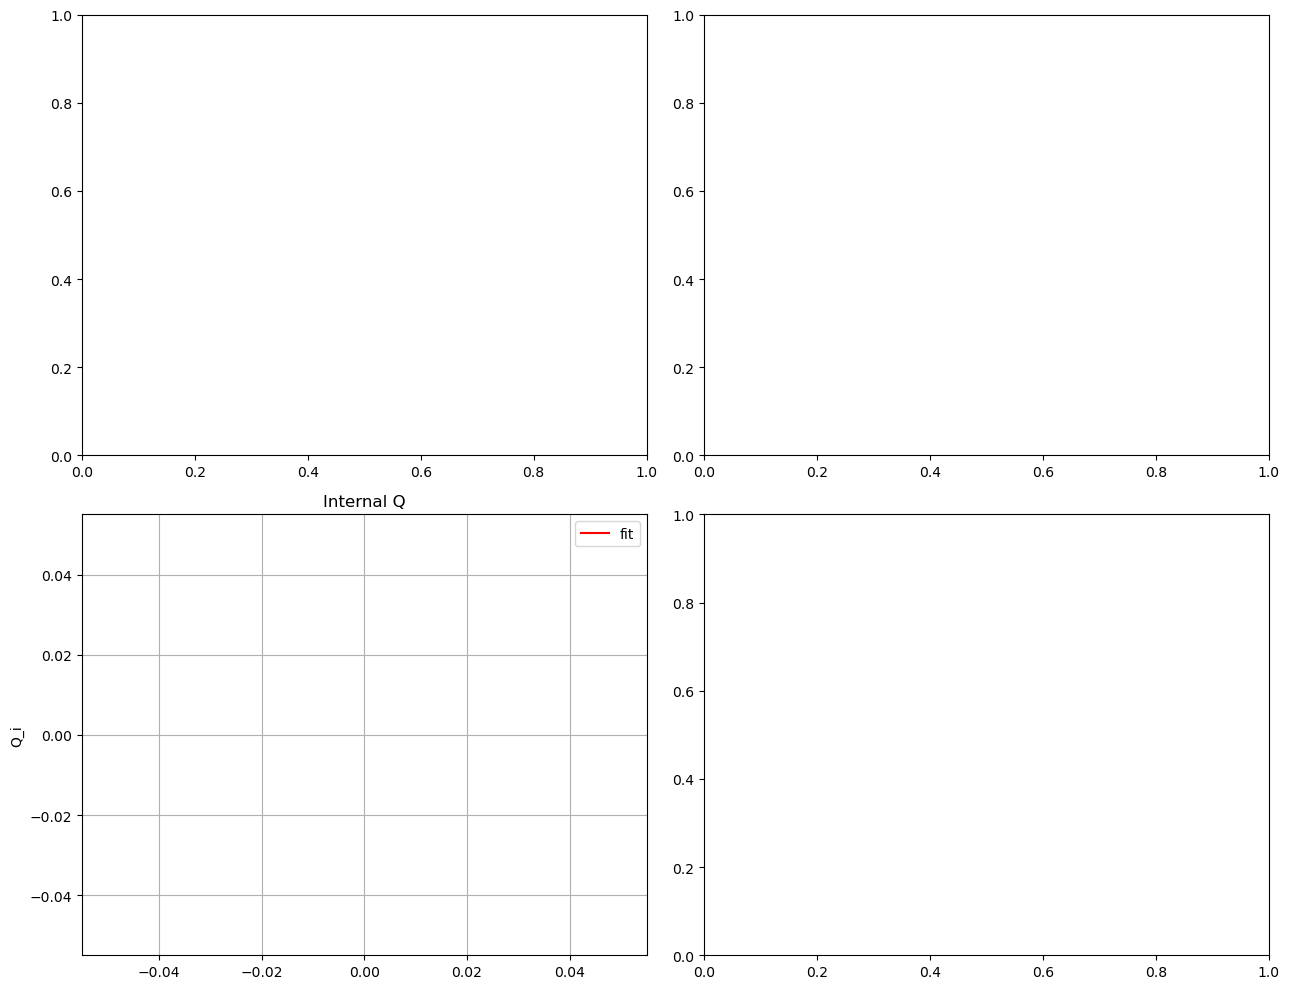

In [64]:
I_plot_uA = np.linspace(I1_full.min(), I1_full.max(), 300)
I_plot_A = I_plot_uA * 1e-6
QL_model, q_i_model, q_e_model, f0_model = model_q_factors(
    I_plot_A, L01_f, L02_f, a_f, Ll_f, Cl_f, Cc_f, Rj_f, M_f, O_f, R_L, (Freq.min()-1e9, Freq.max()+1e9)
)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
# axes[0,0].plot(I1_full, Ql_v2, 'ko-', ms=4, lw=0.8, label='data')
# axes[0,0].plot(I_plot_uA, QL_model, 'r-', lw=1.5, label='fit')
# axes[0,0].set_ylabel('Q_L'); axes[0,0].set_title('Loaded Q (fit target)'); axes[0,0].legend(); axes[0,0].grid(True)

# axes[0,1].plot(I1_full, fr_v2, 'ko-', ms=4, lw=0.8, label='data')
# axes[0,1].plot(I_plot_uA, f0_model, 'r-', lw=1.5, label='fit')
# axes[0,1].set_ylabel('f0 (GHz)'); axes[0,1].set_title('Resonance freq (fit target)'); axes[0,1].legend(); axes[0,1].grid(True)

#axes[1,0].plot(I1_full, Qi_v2, 'ko-', ms=4, lw=0.8, label='data')
axes[1,0].plot(I_plot_uA, (1/q_i_model + 1/Q_alpha_f)**(-1), 'r-', lw=1.5, label='fit')
axes[1,0].set_ylabel('Q_i'); axes[1,0].set_yscale('linear'); axes[1,0].set_title('Internal Q'); axes[1,0].legend(); axes[1,0].grid(True)

# axes[1,1].plot(I1_full, Qc_v2, 'ko-', ms=4, lw=0.8, label='data')
# axes[1,1].plot(I_plot_uA, q_e_model, 'r-', lw=1.5, label='implied')
# axes[1,1].set_ylabel('Q_ext'); axes[1,1].set_title('External Q (diagnostic only)'); axes[1,1].legend(); axes[1,1].grid(True)
plt.tight_layout(); plt.show()

In [66]:
q_i_model

array([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, na